In [1]:
# ============================================================
#  02_weather_cities_models — Setup
# ============================================================
import json
import warnings
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.preprocessing import StandardScaler

try:
    import xgboost as xgb
    HAS_XGB = True
except ImportError:
    HAS_XGB = False

try:
    from statsmodels.tsa.statespace.sarimax import SARIMAX
    HAS_SARIMAX = True
except ImportError:
    HAS_SARIMAX = False

try:
    import torch
    import torch.nn as nn
    HAS_TORCH = True
except ImportError:
    HAS_TORCH = False

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110


def find_project_root(start=None):
    p = Path(start or Path.cwd()).resolve()
    for parent in [p, *p.parents]:
        if (parent / "requirements.txt").exists() and (parent / "notebooks").exists():
            return parent
    raise RuntimeError("Корень проекта не найден")


PROJECT = find_project_root()
DATA_DIR = PROJECT / "data" / "weather" / "cities"
ARTIFACTS_DIR = PROJECT / "artifacts" / "weather" / "cities"
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)

print("PROJECT      :", PROJECT)
print("DATA_DIR     :", DATA_DIR)
print("ARTIFACTS_DIR:", ARTIFACTS_DIR)
print(f"backend      : xgboost={HAS_XGB}, sarimax={HAS_SARIMAX}, torch={HAS_TORCH}")
if not HAS_SARIMAX:
    print("⚠  statsmodels не установлен → SARIMAX будет пропущен (метрики = 0). "
          "Установи: pip install statsmodels")
if not HAS_XGB:
    print("⚠  xgboost не установлен → фолбэк на HistGradientBoostingRegressor.")
if not HAS_TORCH:
    print("ℹ  torch не установлен → LSTM будет пропущен.")

PROJECT      : /app
DATA_DIR     : /app/data/weather/cities
ARTIFACTS_DIR: /app/artifacts/weather/cities
backend      : xgboost=True, sarimax=True, torch=True


In [2]:
# ============================================================
#  Конфиг задачи + загрузка cities_daily.csv
# ============================================================
TRAIN_END  = pd.Timestamp("2021-12-31")
TEST_START = pd.Timestamp("2022-01-01")
TEST_END   = pd.Timestamp("2023-12-31")

# Горизонты
STATION_HORIZONS = list(range(1, 15))       # 1..14
CITY_HORIZONS    = list(range(1, 8))        # 1..7
STATION_H_MAX    = max(STATION_HORIZONS)    # 14

# Окно для city-dashboard (совпадает со структурой фронта)
CITY_N          = 66
CITY_PAST       = 59
CITY_BACK_START = 45
CITY_ORIGIN     = 44
CITY_H_MAX      = CITY_N - CITY_ORIGIN - 1  # 21 день прогноза от origin
assert CITY_H_MAX >= max(CITY_HORIZONS)

# Переменные
VARS = ["temp", "humidity", "precipitation", "wind", "pressure"]
CITY_VAR_MAP = {
    "temp": "temp",
    "hum":  "humidity",
    "rain": "precipitation",
    "wind": "wind",
    "pres": "pressure",
}
CITY_VAR_UNITS = {
    "temp": "°C", "hum": "%", "rain": "мм",
    "wind": "м/с", "pres": "гПа",
}

# Модели
STATION_MODELS = ["Persistence", "Seasonal Naive", "Ridge",
                  "RandomForest", "GradientBoosting", "XGBoost"]
STATION_BASELINES = ("Persistence", "Seasonal Naive")

CITY_MODELS = ["Persistence"]
if HAS_SARIMAX:
    CITY_MODELS.append("SARIMAX")
CITY_MODELS.append("XGBoost")       # без xgboost → HistGradientBoosting-фолбэк
if HAS_TORCH:
    CITY_MODELS.append("LSTM")

cities_daily = pd.read_csv(DATA_DIR / "cities_daily.csv", parse_dates=["date"])
cities_daily = cities_daily.sort_values(["city", "date"]).reset_index(drop=True)

meta = json.loads((DATA_DIR / "cities_daily_meta.json").read_text())

CITY_NAMES = sorted(cities_daily["city"].unique())
CITY_INFO  = {c["city"]: c for c in meta["cities"]}

# Ряды должны быть непрерывными посуточно (на этом держатся все лаги/окна)
for _c in CITY_NAMES:
    _d = cities_daily.loc[cities_daily["city"] == _c, "date"]
    assert _d.is_unique and (_d.diff().dropna() == pd.Timedelta(days=1)).all(), \
        f"{_c}: в ряду есть пропуски/дубли дат"

# Кросс-городские признаки (ячейка 3) выравниваются по позиции → сетки дат должны совпадать
_ref = cities_daily.loc[cities_daily["city"] == CITY_NAMES[0], "date"].reset_index(drop=True)
for _c in CITY_NAMES[1:]:
    _d = cities_daily.loc[cities_daily["city"] == _c, "date"].reset_index(drop=True)
    assert _d.equals(_ref), f"{_c}: сетка дат не совпадает с {CITY_NAMES[0]}"

print(f"Загружено: {cities_daily.shape}")
print(f"Города   : {CITY_NAMES}")
print(f"Период   : {cities_daily['date'].min().date()} → {cities_daily['date'].max().date()}")
print(f"Модели-станции : {STATION_MODELS}")
print(f"Модели-города  : {CITY_MODELS}")


Загружено: (64284, 11)
Города   : ['Almaty', 'Moscow', 'Sarajevo', 'Tbilisi']
Период   : 1980-01-01 → 2023-12-31
Модели-станции : ['Persistence', 'Seasonal Naive', 'Ridge', 'RandomForest', 'GradientBoosting', 'XGBoost']
Модели-города  : ['Persistence', 'SARIMAX', 'XGBoost', 'LSTM']


In [3]:
# ============================================================
#  Метрики (единый формат для обоих дашбордов)
# ============================================================

def safe_mape(y_true: np.ndarray, y_pred: np.ndarray) -> float:
    """MAPE, пропускающий |y_true| < 1e-6.
    ВНИМАНИЕ: для осадков/ветра считается только по «ненулевым» дням и
    сильно завышен — ориентироваться на MAE / WAPE."""
    mask = np.abs(y_true) >= 1e-6
    if mask.sum() == 0:
        return 0.0
    return float(np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100)


def wape(y_true: np.ndarray, y_pred: np.ndarray) -> float:
    """WAPE = Σ|e| / Σ|y|, % — устойчивая замена MAPE для рядов с нулями."""
    denom = float(np.sum(np.abs(y_true)))
    return float(np.sum(np.abs(y_pred - y_true)) / denom * 100) if denom > 1e-9 else 0.0


def compute_metrics(y_true, y_pred, baseline_mae: float | None = None) -> dict:
    """Единый набор метрик, который ждёт фронт."""
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    n = min(len(y_true), len(y_pred))
    if n == 0:
        return dict(mae=0.0, rmse=0.0, r2=0.0, mape=0.0, wape=0.0,
                    bias=0.0, maxError=0.0, medae=0.0, skill=0.0)

    yt, yp = y_true[:n], y_pred[:n]
    err  = yp - yt
    abse = np.abs(err)

    mae   = float(np.mean(abse))
    rmse  = float(np.sqrt(np.mean(err ** 2)))
    ssr   = float(np.sum(err ** 2))
    sst   = float(np.sum((yt - yt.mean()) ** 2))
    r2    = float(1 - ssr / sst) if sst > 0 else 0.0
    mape  = safe_mape(yt, yp)
    wp    = wape(yt, yp)
    bias  = float(np.mean(err))
    mx    = float(np.max(abse)) if n else 0.0
    medae = float(np.median(abse))
    skill = float(1 - mae / baseline_mae) if baseline_mae and baseline_mae > 0 else 0.0

    return dict(mae=mae, rmse=rmse, r2=r2, mape=mape, wape=wp,
                bias=bias, maxError=mx, medae=medae, skill=skill)


def holidays_for(dates: pd.Series) -> list[dict]:
    """Мини-календарь праздников для reference-lines на графике станций."""
    out = []
    for d in dates:
        md = (d.month, d.day)
        if md == (1, 1):
            out.append({"date": d.strftime("%Y-%m-%d"), "icon": "🎄", "label": "Новый год"})
        elif md == (7, 1):
            out.append({"date": d.strftime("%Y-%m-%d"), "icon": "☀️", "label": "Середина года"})
    return out


In [4]:
# ============================================================
#  Общий каркас: климатология → аномалии → признаки origin'а
#  Используется и станциями, и городами.
#
#  Идея: модели прогнозируют НЕ сырое значение, а аномалию
#     a(t) = y(t) − climatology(doy(t))        (climatology — только train)
#  ŷ(t+h) = climatology(t+h) + â(t+h | данные ≤ t)
#  Так деревья/LSTM не должны «изобретать» сезонность, а все признаки
#  считаются строго по данным ≤ t (никаких утечек из будущего).
# ============================================================
ANOM_LAGS = [0, 1, 2, 3, 5, 7, 10, 14, 21, 30]     # lag_0 = сегодняшняя аномалия
ANOM_ROLL = [3, 7, 14, 30]
ANOM_STD  = [7, 30]
MIN_HIST  = 30                                      # первые 30 дней → NaN в признаках


def get_series(city_name: str, var_src: str):
    sub = (cities_daily.loc[cities_daily["city"] == city_name, ["date", var_src]]
           .reset_index(drop=True))
    y = (pd.Series(sub[var_src].astype(float).values)
         .interpolate(limit_direction="both").values)
    return pd.DatetimeIndex(sub["date"]), y


def climatology(dates_train, y_train, smooth: int = 21) -> np.ndarray:
    """Климатология по doy (366 значений), сглаженная по кругу. Только train."""
    doy = pd.DatetimeIndex(dates_train).dayofyear.values
    clim = (pd.Series(y_train).groupby(doy).mean()
            .reindex(range(1, 367)).interpolate(limit_direction="both").values)
    pad = smooth
    ext = np.concatenate([clim[-pad:], clim, clim[:pad]])
    sm = pd.Series(ext).rolling(smooth, center=True, min_periods=1).mean().values
    return sm[pad:-pad]


def clim_at(clim: np.ndarray, dates) -> np.ndarray:
    return clim[pd.DatetimeIndex(dates).dayofyear.values - 1]


def origin_features(a: np.ndarray, dates: pd.DatetimeIndex,
                    clim_o: np.ndarray) -> pd.DataFrame:
    """Признаки на день-origin t. Всё считается по данным ≤ t."""
    s = pd.Series(a)
    cols = {}
    for l in ANOM_LAGS:
        cols[f"a_lag_{l}"] = s.shift(l).values
    for w in ANOM_ROLL:
        cols[f"a_mean_{w}"] = s.rolling(w).mean().values
    for w in ANOM_STD:
        cols[f"a_std_{w}"] = s.rolling(w).std().values
    doy = dates.dayofyear.values
    cols["doy_sin"] = np.sin(2 * np.pi * doy / 365.25)
    cols["doy_cos"] = np.cos(2 * np.pi * doy / 365.25)
    cols["clim_o"]  = clim_o
    return pd.DataFrame(cols)


def stack_X(Xb: np.ndarray, dates: pd.DatetimeIndex, clim: np.ndarray,
            idx: np.ndarray, h: int) -> np.ndarray:
    """Признаки origin + (h, сезонность целевой даты, климатология цели)."""
    idx = np.asarray(idx)
    tgt_doy = (dates[idx] + pd.Timedelta(days=h)).dayofyear.values
    extra = np.column_stack([
        np.full(len(idx), float(h)),
        np.sin(2 * np.pi * tgt_doy / 365.25),
        np.cos(2 * np.pi * tgt_doy / 365.25),
        clim[tgt_doy - 1],
    ])
    return np.hstack([Xb[idx], extra])


def postprocess(var_src: str, pred: np.ndarray) -> np.ndarray:
    """Физичный диапазон: осадки/ветер ≥ 0, влажность 0..100."""
    if var_src in ("precipitation", "wind"):
        return np.maximum(pred, 0.0)
    if var_src == "humidity":
        return np.clip(pred, 0.0, 100.0)
    return pred


_ANOM_CACHE: dict = {}


def get_anom(city_name: str, var_src: str):
    """(dates, y, clim, anomaly) для любой пары город/переменная; климатология — по train."""
    key = (city_name, var_src)
    if key not in _ANOM_CACHE:
        dts, yv = get_series(city_name, var_src)
        n_tr = int((dts <= TRAIN_END).sum())
        cl = climatology(dts[:n_tr], yv[:n_tr])
        _ANOM_CACHE[key] = (dts, yv, cl, yv - clim_at(cl, dts))
    return _ANOM_CACHE[key]


def extra_features(city_name: str, var_src: str, cross_city: bool = True) -> pd.DataFrame:
    """
    Что ещё «знает» о завтрашней погоде, кроме самой температуры:
      * ДРУГИЕ переменные этого же города: аномалия сегодня, изменение за 1 и 3 дня
        (падение давления, рост ветра/влажности — предвестники фронта), среднее за 7 дней;
      * ВСЕ переменные ДРУГИХ городов: аномалия сегодня и изменение за 1 день
        (то, что уже пришло в соседний регион, может прийти сюда).
    Всё считается по данным ≤ t (diff/rolling смотрят только назад).
    """
    cols = {}
    for v in VARS:
        if v == var_src:
            continue
        s = pd.Series(get_anom(city_name, v)[3])
        cols[f"{v}_a0"] = s.values
        cols[f"{v}_d1"] = s.diff(1).values
        cols[f"{v}_d3"] = s.diff(3).values
        cols[f"{v}_m7"] = s.rolling(7).mean().values
    if cross_city:
        for c in CITY_NAMES:
            if c == city_name:
                continue
            for v in VARS:
                s = pd.Series(get_anom(c, v)[3])
                cols[f"x_{c}_{v}_a0"] = s.values
                cols[f"x_{c}_{v}_d1"] = s.diff(1).values
    return pd.DataFrame(cols)


def make_ctx(city_name: str, var_src: str, H: int, multivar: bool = True) -> dict:
    """
    Контекст одного ряда.
      origins — все дни-origin, для которых хотя бы один горизонт 1..H
                попадает в тестовое окно:  n_train−H … n_end−2.
      Пара (origin o, горизонт h) учитывается в метриках, если дата цели
      o+h лежит в [TEST_START, TEST_END]. Одна и та же выборка у ВСЕХ
      моделей → честный skill.
    """
    dates, y = get_series(city_name, var_src)
    n_train = int((dates <= TRAIN_END).sum())
    n_end   = int((dates <= TEST_END).sum())
    origins = np.arange(n_train - H, n_end - 1)

    clim     = climatology(dates[:n_train], y[:n_train])      # строго train
    clim_all = clim_at(clim, dates)
    a        = y - clim_all
    feats    = origin_features(a, dates, clim_all)
    if multivar:
        feats = pd.concat([feats, extra_features(city_name, var_src)], axis=1)

    # Для LSTM: аномалии остальных переменных этого города (в σ-единицах train)
    seq_extra = np.column_stack([
        get_anom(city_name, v)[3] / (np.std(get_anom(city_name, v)[3][:n_train]) + 1e-9)
        for v in VARS if v != var_src
    ]) if multivar else np.empty((len(y), 0))

    clim_tgt = np.empty((len(origins), H))
    for h in range(1, H + 1):
        tgt_doy = (dates[origins] + pd.Timedelta(days=h)).dayofyear.values
        clim_tgt[:, h - 1] = clim[tgt_doy - 1]

    return dict(city=city_name, var_src=var_src, H=H,
                y=y, a=a, dates=dates, clim=clim,
                Xb=feats.values.astype(float), cols=list(feats.columns),
                n_train=n_train, n_end=n_end, seq_extra=seq_extra,
                origins=origins, clim_tgt=clim_tgt)


def eval_matrix(ctx: dict, pred: np.ndarray, base_mae_by_h: dict | None = None,
                with_points: bool = False) -> dict:
    """
    pred — [n_origins, H] абсолютный прогноз.
    Возвращает {h: {metrics, resid_std, n, (points)}} на ОДНОЙ выборке для всех моделей.
    Точки: date = дата ЦЕЛИ (того дня, который предсказывали), originDate — день прогноза.
    """
    base_mae_by_h = base_mae_by_h or {}
    y, o, dates = ctx["y"], ctx["origins"], ctx["dates"]
    n_train, n_end = ctx["n_train"], ctx["n_end"]
    res = {}
    for h in range(1, ctx["H"] + 1):
        tgt = o + h
        ok = (tgt >= n_train) & (tgt <= n_end - 1)
        yt = y[tgt[ok]]
        yp = pred[ok, h - 1]
        cell = {
            "metrics":   compute_metrics(yt, yp, baseline_mae=base_mae_by_h.get(h)),
            "resid_std": float(np.std(yp - yt)) if len(yt) else 0.0,
            "n":         int(len(yt)),
        }
        if with_points:
            t_dates = dates[tgt[ok]].strftime("%Y-%m-%d")
            o_dates = dates[o[ok]].strftime("%Y-%m-%d")
            cell["points"] = [
                {"date": td, "originDate": od,
                 "actual": float(a_), "predicted": float(p_)}
                for td, od, a_, p_ in zip(t_dates, o_dates, yt, yp)
            ]
        res[h] = cell
    return res


print(f"ANOM_LAGS = {ANOM_LAGS}")
print(f"ROLL      = {ANOM_ROLL}, STD = {ANOM_STD}")


ANOM_LAGS = [0, 1, 2, 3, 5, 7, 10, 14, 21, 30]
ROLL      = [3, 7, 14, 30], STD = [7, 30]


In [5]:
# ============================================================
#  Модели (общие для станций и городов) → predict(origins) → [n, H]
#
#  Все модели:
#   * обучаются ТОЛЬКО на целях ≤ TRAIN_END,
#   * на входе — факт ≤ origin,
#   * прогнозируют аномалию (кроме Persistence / Seasonal Naive),
#   * без рекурсии: direct по горизонту.
# ============================================================
from sklearn.ensemble import HistGradientBoostingRegressor
from numpy.lib.stride_tricks import sliding_window_view


# ---------- общий линейный блок ----------
def _fit_ridges(ctx: dict, alpha: float = 10.0):
    Xb, a, n_train, H = ctx["Xb"], ctx["a"], ctx["n_train"], ctx["H"]
    fin = np.isfinite(Xb).all(axis=1) & (np.arange(len(Xb)) < n_train)
    scaler = StandardScaler().fit(Xb[fin])
    Xz = scaler.transform(np.nan_to_num(Xb))
    ridges = {}
    for h in range(1, H + 1):
        idx = np.arange(MIN_HIST, n_train - h)            # цель t+h ≤ train_end
        ridges[h] = Ridge(alpha=alpha).fit(Xz[idx], a[idx + h])
    return ridges, Xz


def build_ridge(ctx):
    ridges, Xz = _fit_ridges(ctx)
    H = ctx["H"]

    def predict(origins):
        origins = np.asarray(origins)
        return np.column_stack([ridges[h].predict(Xz[origins]) for h in range(1, H + 1)])
    return predict


# ---------- деревья: отдельная модель на каждый h (станции) ----------
def _make_tree(kind: str):
    if kind == "RandomForest":
        return RandomForestRegressor(n_estimators=100, max_depth=12, max_features=0.5,
                                     min_samples_leaf=10, n_jobs=-1, random_state=42)
    if kind == "GradientBoosting":
        return GradientBoostingRegressor(n_estimators=150, learning_rate=0.05,
                                         max_depth=3, subsample=0.8, random_state=42)
    if kind == "XGBoost":
        if HAS_XGB:
            return xgb.XGBRegressor(n_estimators=300, learning_rate=0.04, max_depth=4,
                                    subsample=0.8, colsample_bytree=0.8,
                                    min_child_weight=10, tree_method="hist",
                                    n_jobs=-1, random_state=42, verbosity=0)
        return HistGradientBoostingRegressor(max_iter=300, learning_rate=0.04,
                                             max_depth=4, min_samples_leaf=20,
                                             random_state=42)
    raise ValueError(kind)


def build_tree(ctx, kind: str):
    Xb, a, dates, clim = ctx["Xb"], ctx["a"], ctx["dates"], ctx["clim"]
    n_train, H = ctx["n_train"], ctx["H"]
    models = {}
    for h in range(1, H + 1):
        idx = np.arange(MIN_HIST, n_train - h)
        X, y = stack_X(Xb, dates, clim, idx, h), a[idx + h]
        ok = np.isfinite(X).all(axis=1) & np.isfinite(y)
        models[h] = _make_tree(kind).fit(X[ok], y[ok])

    def predict(origins):
        origins = np.asarray(origins)
        return np.column_stack([
            models[h].predict(stack_X(Xb, dates, clim, origins, h))
            for h in range(1, H + 1)
        ])
    return predict


# ---------- XGBoost для городов: Ridge по h + ОДИН бустинг на остатках ----------
def _fit_gbm_stacked(X, y):
    if HAS_XGB:
        return xgb.XGBRegressor(
            n_estimators=200, learning_rate=0.05, max_depth=5,
            subsample=0.8, colsample_bytree=0.8, min_child_weight=20,
            tree_method="hist", n_jobs=-1, random_state=42, verbosity=0,
        ).fit(X, y)
    return HistGradientBoostingRegressor(
        max_iter=200, learning_rate=0.05, max_depth=5,
        min_samples_leaf=40, random_state=42,
    ).fit(X, y)


def build_xgb_resid(ctx):
    """Аномалии почти линейны (AR-подобны) → Ridge берёт основную часть сигнала,
    бустинг (с признаком h) учится только на остатках."""
    Xb, a, dates, clim = ctx["Xb"], ctx["a"], ctx["dates"], ctx["clim"]
    n_train, H = ctx["n_train"], ctx["H"]
    ridges, Xz = _fit_ridges(ctx)

    h_train = sorted({h for h in (set(range(1, 8)) | {9, 11, 14, 17, 21, H}) if h <= H})
    Xs, ys = [], []
    for h in h_train:
        idx = np.arange(MIN_HIST, n_train - h)
        X = stack_X(Xb, dates, clim, idx, h)
        y = a[idx + h] - ridges[h].predict(Xz[idx])
        ok = np.isfinite(X).all(axis=1) & np.isfinite(y)
        Xs.append(X[ok]); ys.append(y[ok])
    gbm = _fit_gbm_stacked(np.vstack(Xs), np.concatenate(ys))

    def predict(origins):
        origins = np.asarray(origins)
        out = np.empty((len(origins), H))
        for h in range(1, H + 1):
            out[:, h - 1] = (ridges[h].predict(Xz[origins])
                             + gbm.predict(stack_X(Xb, dates, clim, origins, h)))
        return out
    return predict


# ---------- LSTM: direct multi-output ----------
LSTM_LOOKBACK = 30
LSTM_HIDDEN   = 48
LSTM_EPOCHS   = 20
LSTM_BATCH    = 256

if HAS_TORCH:
    class _LSTMNet(nn.Module):
        """Вход: 30 дней × (аномалия цели, аномалии др. переменных, sin, cos). Выход: H шагов."""
        def __init__(self, horizon: int, n_in: int = 3, hidden: int = LSTM_HIDDEN):
            super().__init__()
            self.lstm = nn.LSTM(n_in, hidden, batch_first=True)
            self.head = nn.Sequential(nn.Linear(hidden, hidden), nn.ReLU(),
                                      nn.Linear(hidden, horizon))

        def forward(self, x):
            o, _ = self.lstm(x)
            return self.head(o[:, -1, :])


def build_lstm(ctx):
    a, dates, n_train, H = ctx["a"], ctx["dates"], ctx["n_train"], ctx["H"]
    LB = LSTM_LOOKBACK
    sd_a = float(np.std(a[:n_train])) + 1e-9
    az = a / sd_a
    doy = dates.dayofyear.values
    chan = np.column_stack([az, ctx["seq_extra"],
                            np.sin(2 * np.pi * doy / 365.25),
                            np.cos(2 * np.pi * doy / 365.25)]).astype(np.float32)
    wins = sliding_window_view(chan, LB, axis=0)                   # (N-LB+1, 3, LB)
    wins = np.ascontiguousarray(wins.transpose(0, 2, 1))           # (N-LB+1, LB, 3)

    tr_orig = np.arange(LB - 1, n_train - H)                       # цель t+H ≤ train_end
    Y = np.stack([az[tr_orig + h] for h in range(1, H + 1)], axis=1).astype(np.float32)
    Xtr = torch.from_numpy(wins[tr_orig - (LB - 1)])
    Ytr = torch.from_numpy(Y)

    torch.manual_seed(42)
    net = _LSTMNet(H, n_in=chan.shape[1])
    opt = torch.optim.AdamW(net.parameters(), lr=3e-3, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=LSTM_EPOCHS)
    loss_fn = nn.MSELoss()
    n = len(Xtr)
    for _ in range(LSTM_EPOCHS):
        net.train()
        perm = torch.randperm(n)
        for b in range(0, n, LSTM_BATCH):
            ib = perm[b:b + LSTM_BATCH]
            opt.zero_grad()
            loss_fn(net(Xtr[ib]), Ytr[ib]).backward()
            opt.step()
        sched.step()
    net.eval()

    def predict(origins):
        with torch.no_grad():
            xb = torch.from_numpy(wins[np.asarray(origins) - (LB - 1)])
            return net(xb).numpy().astype(float) * sd_a
    return predict


# ---------- SARIMAX: ARMA на аномалиях ----------
SARIMAX_ORDER  = (2, 0, 1)
SARIMAX_WINDOW = 90


def build_sarimax(ctx):
    a, n_train, H = ctx["a"], ctx["n_train"], ctx["H"]
    res = SARIMAX(a[:n_train][-3000:], order=SARIMAX_ORDER,
                  enforce_stationarity=True,
                  enforce_invertibility=True).fit(disp=False)
    params = np.asarray(res.params)
    decay = np.exp(-np.arange(1, H + 1) / 3.0)

    def predict(origins):
        out = np.empty((len(origins), H))
        for k, t in enumerate(origins):
            w = a[max(0, t - SARIMAX_WINDOW + 1): t + 1]           # только факт ≤ origin
            try:
                m = SARIMAX(w, order=SARIMAX_ORDER,
                            enforce_stationarity=True, enforce_invertibility=True)
                fc = np.asarray(m.filter(params).forecast(steps=H), dtype=float)
                if not np.all(np.isfinite(fc)):
                    raise ValueError("NaN/Inf")
            except Exception:
                fc = a[t] * decay
            out[k] = fc
        return out
    return predict


# ---------- реестры ----------
STATION_BUILDERS = {
    "Ridge":            build_ridge,
    "RandomForest":     lambda c: build_tree(c, "RandomForest"),
    "GradientBoosting": lambda c: build_tree(c, "GradientBoosting"),
    "XGBoost":          lambda c: build_tree(c, "XGBoost"),
}
CITY_BUILDERS = {
    "XGBoost": build_xgb_resid,
    "LSTM":    build_lstm if HAS_TORCH else None,
    "SARIMAX": build_sarimax if HAS_SARIMAX else None,
}


def model_matrix(model_name: str, ctx: dict, builders: dict) -> np.ndarray:
    """Абсолютный прогноз [n_origins, H] на всех origin'ах."""
    o, y, H = ctx["origins"], ctx["y"], ctx["H"]
    if model_name == "Persistence":
        pred = np.repeat(y[o][:, None], H, axis=1)
    elif model_name == "Seasonal Naive":
        # y(t+h) ≈ y(t+h−365); при h ≤ 21 это всегда известное прошлое
        pred = np.column_stack([y[np.maximum(o + h - 365, 0)] for h in range(1, H + 1)])
    else:
        pred = ctx["clim_tgt"] + builders[model_name](ctx)(o)
    return postprocess(ctx["var_src"], pred)


print("Модели готовы:",
      "станции =", list(STATION_BUILDERS),
      "| города =", [k for k, v in CITY_BUILDERS.items() if v])


Модели готовы: станции = ['Ridge', 'RandomForest', 'GradientBoosting', 'XGBoost'] | города = ['XGBoost', 'LSTM', 'SARIMAX']


In [6]:
# ============================================================
#  Station benchmark: 4 города × 6 моделей × 14 горизонтов
#  (одна переменная — temp)
#
#  Все модели оцениваются на ОДНОЙ выборке пар (origin, h):
#  дата цели ∈ [TEST_START, TEST_END]. Обучение — на ВСЕЙ истории
#  до TRAIN_END (раньше модели видели только ~370 последних дней).
# ============================================================
print("=" * 64)
print("STATION BENCHMARK — 4 города × 6 моделей × 14 горизонтов")
print("=" * 64)

station_results: dict[str, dict] = {}
station_ctx: dict[str, dict] = {}


def _cells_from_eval(ev: dict, base_mae: dict | None) -> dict:
    return {
        h: {
            "points":  c["points"],
            "metrics": c["metrics"],
            "deltaVsPersistence": (c["metrics"]["mae"] - base_mae[h]) if base_mae else 0.0,
        }
        for h, c in ev.items()
    }


for city_name in CITY_NAMES:
    ctx = make_ctx(city_name, "temp", STATION_H_MAX)
    station_ctx[city_name] = ctx
    print(f"\n[{city_name}]  n={len(ctx['y']):,}  train≤{TRAIN_END.date()}  "
          f"test={TEST_START.date()}→{TEST_END.date()}")

    city_eval: dict[str, dict] = {}

    # 1) Persistence — база skill
    pred_p = model_matrix("Persistence", ctx, {})
    ev_p   = eval_matrix(ctx, pred_p, with_points=True)
    base_mae = {h: ev_p[h]["metrics"]["mae"] for h in ev_p}
    city_eval["Persistence"] = _cells_from_eval(ev_p, None)
    print(f"  {'Persistence':16s} ok  MAE(h=7) = {ev_p[7]['metrics']['mae']:.3f}")

    # 2) Остальные
    for m in STATION_MODELS:
        if m == "Persistence":
            continue
        try:
            pred = model_matrix(m, ctx, STATION_BUILDERS)
            if not np.all(np.isfinite(pred)):
                raise ValueError("NaN/Inf в прогнозе")
            ev = eval_matrix(ctx, pred, base_mae, with_points=True)
            city_eval[m] = _cells_from_eval(ev, base_mae)
            print(f"  {m:16s} ok  MAE(h=7) = {ev[7]['metrics']['mae']:.3f}  "
                  f"skill = {ev[7]['metrics']['skill']:+.3f}")
        except Exception as e:
            print(f"  {m:16s} FAIL — {e}")

    station_results[city_name] = city_eval

print("\nГотово.")


STATION BENCHMARK — 4 города × 6 моделей × 14 горизонтов

[Almaty]  n=16,071  train≤2021-12-31  test=2022-01-01→2023-12-31
  Persistence      ok  MAE(h=7) = 4.443
  Seasonal Naive   ok  MAE(h=7) = 4.944  skill = -0.113
  Ridge            ok  MAE(h=7) = 3.253  skill = +0.268
  RandomForest     ok  MAE(h=7) = 3.290  skill = +0.260
  GradientBoosting ok  MAE(h=7) = 3.280  skill = +0.262
  XGBoost          ok  MAE(h=7) = 3.266  skill = +0.265

[Moscow]  n=16,071  train≤2021-12-31  test=2022-01-01→2023-12-31
  Persistence      ok  MAE(h=7) = 4.095
  Seasonal Naive   ok  MAE(h=7) = 4.623  skill = -0.129
  Ridge            ok  MAE(h=7) = 3.213  skill = +0.215
  RandomForest     ok  MAE(h=7) = 3.134  skill = +0.235
  GradientBoosting ok  MAE(h=7) = 3.161  skill = +0.228
  XGBoost          ok  MAE(h=7) = 3.174  skill = +0.225

[Sarajevo]  n=16,071  train≤2021-12-31  test=2022-01-01→2023-12-31
  Persistence      ok  MAE(h=7) = 3.247
  Seasonal Naive   ok  MAE(h=7) = 3.472  skill = -0.069
  Ridge

In [7]:
# ============================================================
#  Сериализация station benchmark → stations.json
#  Формат: совместим с lib/data/demoWeather.ts
#
#  Изменения:
#   * point.date — дата ЦЕЛИ (раньше стояла дата origin, а actual был
#     y(t+h) → факт на графике был сдвинут на h дней). Дата origin
#     лежит в point.originDate.
#   * testStart — индекс начала теста ВНУТРИ series (раньше считался по
#     полному ряду, ~15 700 при длине series=200). Плюс testStartDate.
#   * JSON пишется компактно (без indent) — в разы меньше файл.
# ============================================================
SERIES_TAIL      = 200   # сколько последних дней кладём в series (для графика)
MAX_POINTS_PER_H = 100   # сколько последних точек бэктеста храним на горизонт


def _make_series(sub: pd.DataFrame) -> list[dict]:
    tail = sub.tail(SERIES_TAIL).copy()
    hol = {h["date"]: h for h in holidays_for(tail["date"])}
    out = []
    for _, row in tail.iterrows():
        d = row["date"].strftime("%Y-%m-%d")
        item = {"date": d, "actual": float(row["y"])}
        if d in hol:
            item["holiday"] = hol[d]["label"]
        out.append(item)
    return out


def _serialize_station_evals(evals: dict) -> dict:
    """{h: {...}} → {"1": {...}, ...} — фронт использует строковые ключи."""
    out = {}
    for h, cell in evals.items():
        m = cell.get("metrics", {})
        mae = float(m.get("mae", 0.0))
        all_pts = cell.get("points", [])
        trimmed = all_pts[-MAX_POINTS_PER_H:] if len(all_pts) > MAX_POINTS_PER_H else all_pts

        pts = []
        for p in trimmed:
            err = p["predicted"] - p["actual"]
            pts.append({
                "date": p["date"],
                "originDate": p.get("originDate"),
                "actual": round(p["actual"], 3),
                "predicted": round(p["predicted"], 3),
                "error": round(err, 3),
                "abs_error": round(abs(err), 3),
                "within_mae": abs(err) <= mae,
                "is_outlier": abs(err) > mae * 2.5,
            })
        out[str(h)] = {
            "horizon": h,
            "model": None,
            "points": pts,
            "pointsTotal": len(all_pts),
            "metrics": {k: round(float(v), 5) for k, v in m.items()},
            "deltaVsPersistence": round(float(cell.get("deltaVsPersistence", 0.0)), 5),
        }
    return out


# --- Feature importance (те же признаки, что у моделей; h=1) --------------
feature_importance = []
try:
    _ctx = station_ctx[CITY_NAMES[0]]
    idx = np.arange(MIN_HIST, _ctx["n_train"] - 1)
    X_fi, y_fi = _ctx["Xb"][idx], _ctx["a"][idx + 1]
    ok = np.isfinite(X_fi).all(axis=1) & np.isfinite(y_fi)
    rf = RandomForestRegressor(n_estimators=100, max_depth=10, min_samples_leaf=20,
                               n_jobs=-1, random_state=42).fit(X_fi[ok], y_fi[ok])
    pairs = sorted(zip(_ctx["cols"], rf.feature_importances_), key=lambda kv: -kv[1])[:10]
    total = sum(v for _, v in pairs) or 1.0
    feature_importance = [{"name": k, "value": round(float(v / total), 4)} for k, v in pairs]
except Exception as e:
    print("feature_importance fallback:", e)
    feature_importance = [{"name": c, "value": 0.0} for c in ["a_lag_0", "a_lag_1"]]


# --- stationData ---------------------------------------------------------
station_data = []
for city_name in CITY_NAMES:
    info = CITY_INFO[city_name]
    dts, yv = get_series(city_name, "temp")
    sub = pd.DataFrame({"date": dts, "y": yv})

    serialized_evals = {}
    for m in STATION_MODELS:
        if m not in station_results[city_name]:
            continue
        serialized_evals[m] = _serialize_station_evals(station_results[city_name][m])
        for h_key in serialized_evals[m]:
            serialized_evals[m][h_key]["model"] = m

    series = _make_series(sub)
    first_test_in_series = next((i for i, it in enumerate(series)
                                 if pd.Timestamp(it["date"]) >= TEST_START), len(series))

    station_data.append({
        "station": {
            "id": info["wmo_id"],
            "label": info["city_ru"],
            "lat": info["lat"],
            "lon": info["lon"],
            "meanT": float(sub["y"].mean()),
            "seasonalAmp": float(sub["y"].max() - sub["y"].min()),
            "noise": float(sub["y"].std() - (sub["y"].max() - sub["y"].min()) / 6),
        },
        "series": series,
        "testStart": int(first_test_in_series),
        "testStartDate": TEST_START.strftime("%Y-%m-%d"),
        "evaluations": serialized_evals,
    })


stations_artifact = {
    "section": "forecasting-weather",
    "source": "open-meteo archive · real data",
    "generatedAt": datetime.now().isoformat(),
    "stations": [
        {"id": CITY_INFO[c]["wmo_id"], "label": CITY_INFO[c]["city_ru"]}
        for c in CITY_NAMES
    ],
    "models": [
        {"name": "Persistence",       "isBaseline": True,  "model": "ŷ(t+h)=y(t)", "description": "Последнее наблюдение"},
        {"name": "Seasonal Naive",    "isBaseline": True,  "model": "ŷ(t+h)=y(t+h−365)", "description": "Год назад"},
        {"name": "Ridge",             "isBaseline": False, "model": "Ridge(α=10) на аномалиях", "description": "Линейная регрессия L2"},
        {"name": "RandomForest",      "isBaseline": False, "model": "RF(n=100, d=12) на аномалиях", "description": "Ансамбль деревьев"},
        {"name": "GradientBoosting",  "isBaseline": False, "model": "GBM(lr=0.05, d=3) на аномалиях", "description": "Градиентный бустинг"},
        {"name": "XGBoost",           "isBaseline": False, "model": "XGB(d=4, lr=0.04) на аномалиях", "description": "XGBoost"},
    ],
    "horizons": STATION_HORIZONS,
    "stationData": station_data,
    "featureImportance": feature_importance,
    "seriesLength": SERIES_TAIL,
    "pointsPerHorizon": MAX_POINTS_PER_H,
    "trainCount": int((cities_daily["date"] <= TRAIN_END).sum() // len(CITY_NAMES)),
    "testDays": int(((cities_daily["date"] >= TEST_START) &
                     (cities_daily["date"] <= TEST_END)).sum() // len(CITY_NAMES)),
}

out_path = ARTIFACTS_DIR / "stations.json"
out_path.write_text(json.dumps(stations_artifact, ensure_ascii=False, separators=(",", ":")))
print(f"saved → {out_path}  ({out_path.stat().st_size/1024:.1f} KB)")


saved → /app/artifacts/weather/cities/stations.json  (4966.1 KB)


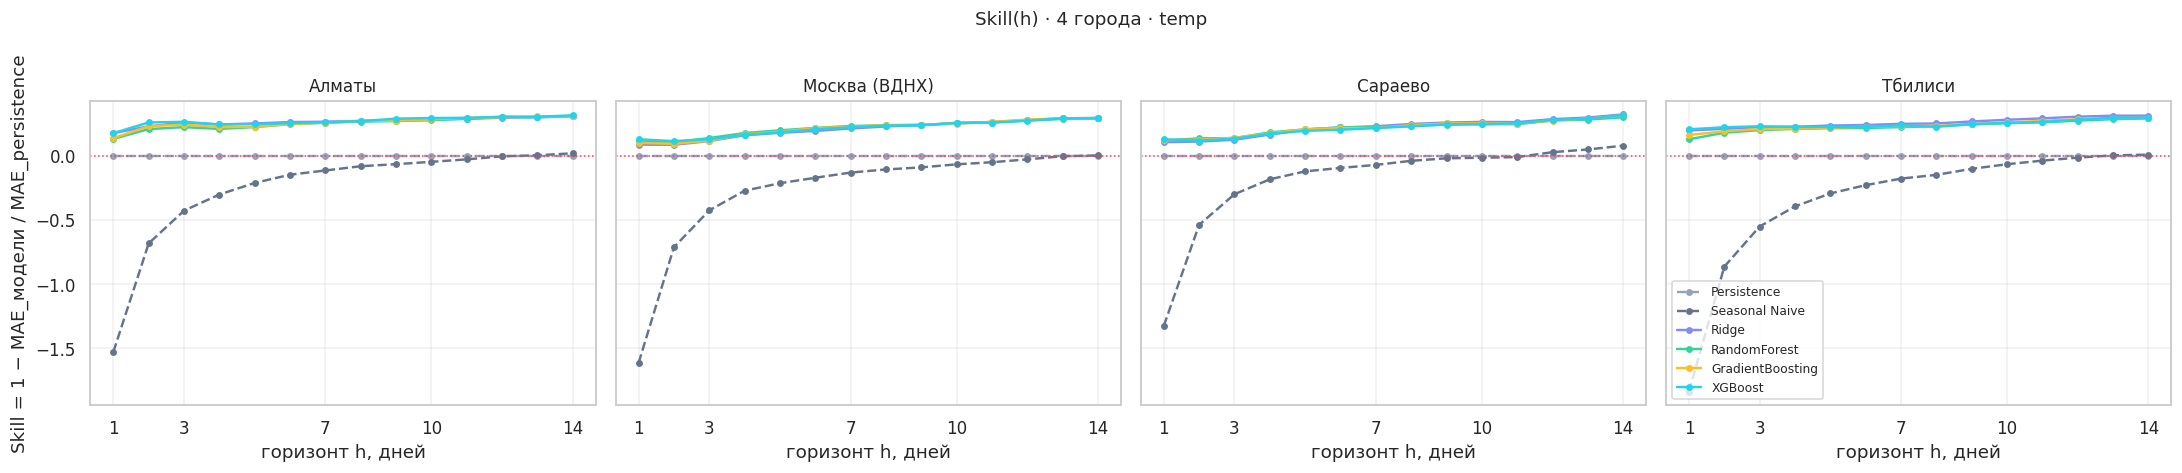

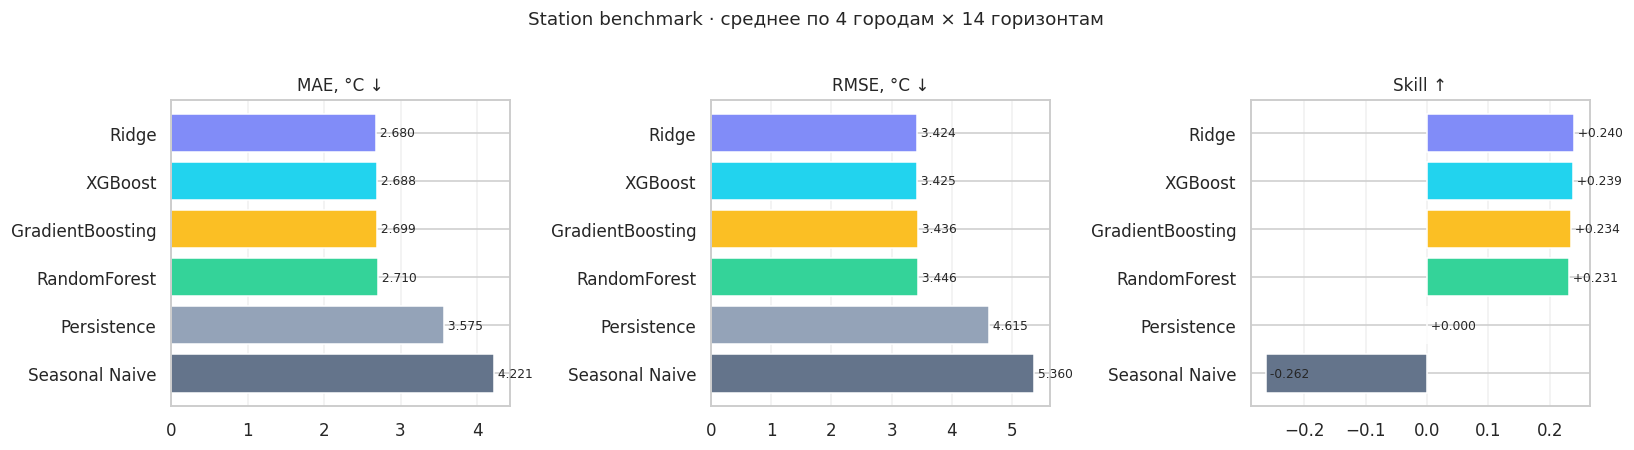

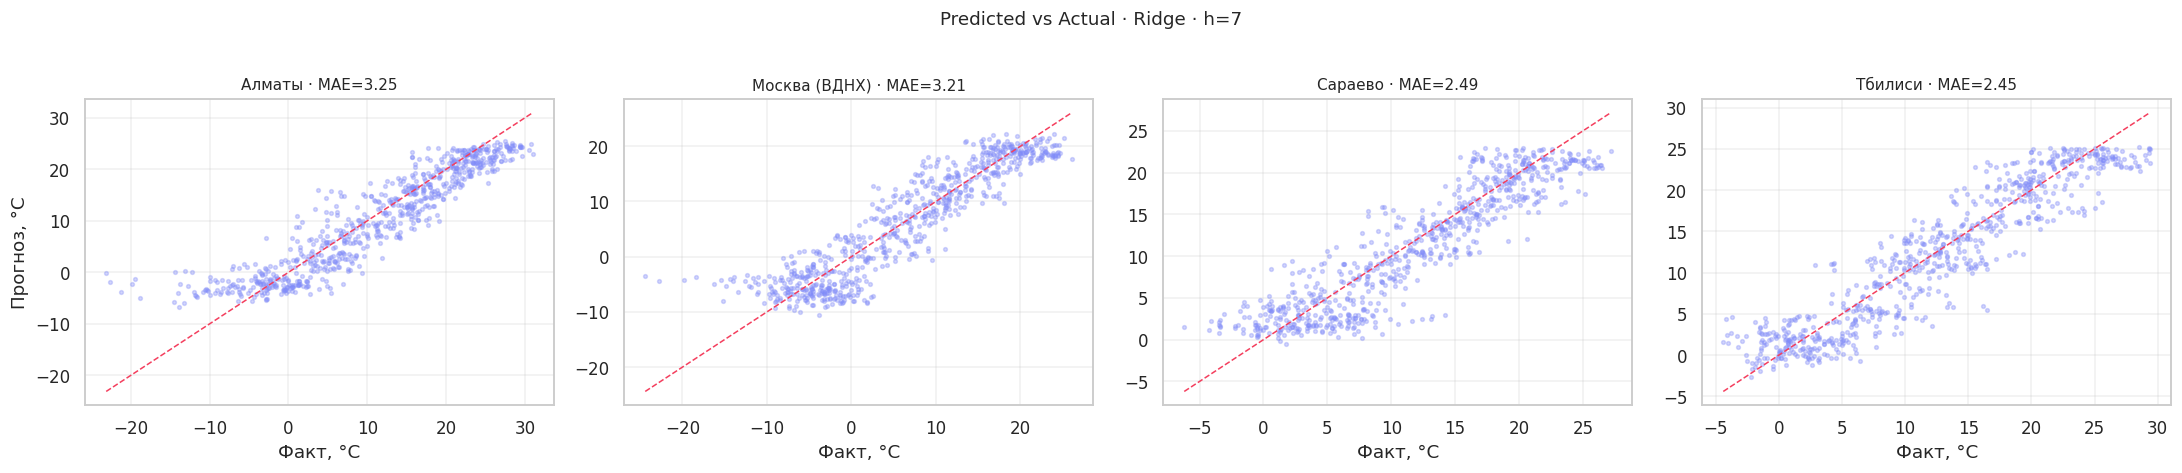

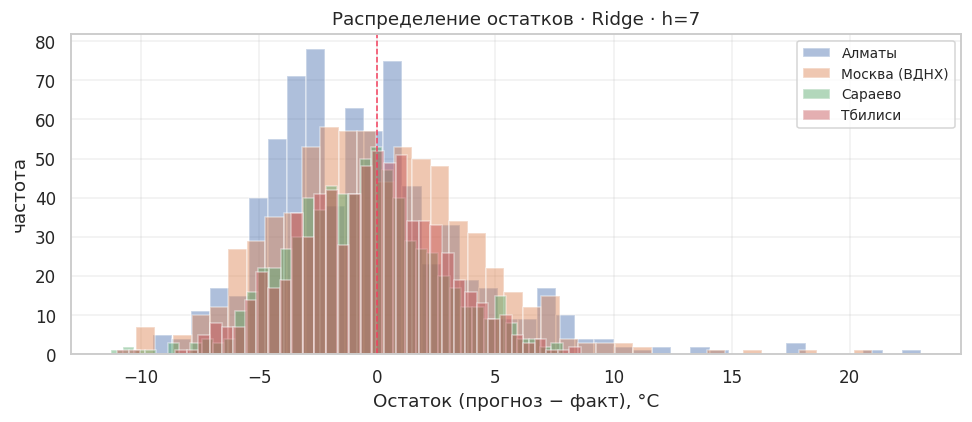

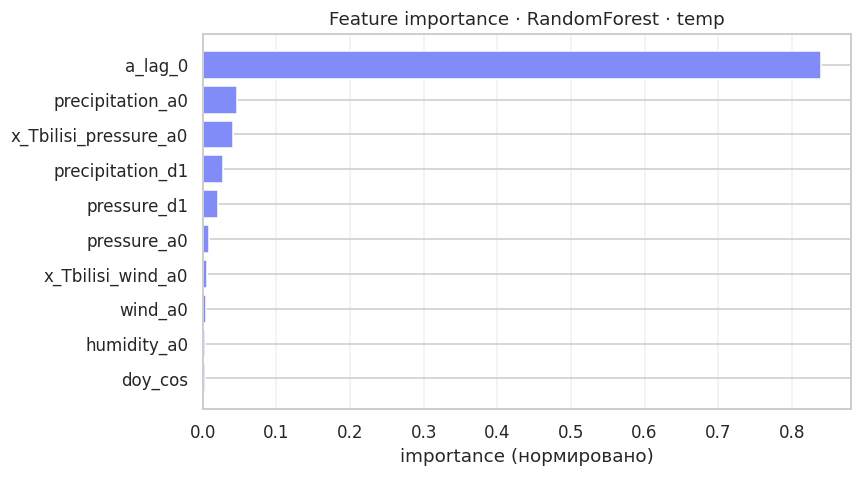


Фигуры сохранены в /app/artifacts/weather/cities/figures


In [8]:
# ============================================================
#  Визуализации station benchmark
#  → artifacts/weather/cities/figures/stations_*.png
# ============================================================
FIG_DIR = ARTIFACTS_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

PALETTE = {
    "Persistence":      "#94a3b8",
    "Seasonal Naive":   "#64748b",
    "Ridge":            "#818cf8",
    "RandomForest":     "#34d399",
    "GradientBoosting": "#fbbf24",
    "XGBoost":          "#22d3ee",
}

# ---------- 1. Skill(h) по горизонтам для каждой станции ----------
fig, axes = plt.subplots(1, len(CITY_NAMES), figsize=(5 * len(CITY_NAMES), 4.2),
                         sharey=True)
if len(CITY_NAMES) == 1:
    axes = [axes]

for ax, city_name in zip(axes, CITY_NAMES):
    per_model = station_results[city_name]           # {model_name: {h: cell}}
    for m in STATION_MODELS:
        if m not in per_model:
            continue
        model_evals = per_model[m]                   # {h: {points, metrics}}
        skills = []
        for h in STATION_HORIZONS:
            cell = model_evals.get(h) or model_evals.get(str(h))
            if cell is None or "metrics" not in cell:
                skills.append(np.nan)
            else:
                skills.append(cell["metrics"]["skill"])
        ax.plot(STATION_HORIZONS, skills, marker="o", ms=3.5, lw=1.6,
                color=PALETTE.get(m, "gray"),
                linestyle="--" if m in ("Persistence", "Seasonal Naive") else "-",
                label=m)
    ax.axhline(0, color="#f43f5e", lw=1, linestyle=":")
    ax.set_title(CITY_INFO[city_name]["city_ru"], fontsize=11)
    ax.set_xlabel("горизонт h, дней")
    ax.set_xticks([1, 3, 7, 10, 14])
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Skill = 1 − MAE_модели / MAE_persistence")
axes[-1].legend(loc="lower left", fontsize=8)
fig.suptitle("Skill(h) · 4 города · temp", fontsize=12, y=1.02)
plt.tight_layout()
plt.savefig(FIG_DIR / "stations_skill_by_horizon.png", dpi=110, bbox_inches="tight")
plt.show()


# ---------- 2. Средний MAE по моделям (bar) ----------
rows = []
for m in STATION_MODELS:
    cells = []
    for city_name in CITY_NAMES:
        per_model = station_results[city_name]
        if m not in per_model:
            continue
        model_evals = per_model[m]
        for h in STATION_HORIZONS:
            cell = model_evals.get(h) or model_evals.get(str(h))
            if cell and cell.get("points") and cell.get("metrics"):
                cells.append(cell["metrics"])
    if cells:
        rows.append({
            "model": m,
            "mae":   float(np.mean([c["mae"] for c in cells])),
            "rmse":  float(np.mean([c["rmse"] for c in cells])),
            "skill": float(np.mean([c["skill"] for c in cells])),
        })

df_st = pd.DataFrame(rows).sort_values("mae") if rows else pd.DataFrame()
if not df_st.empty:
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for ax, metric, label in zip(axes, ["mae", "rmse", "skill"],
                                  ["MAE, °C ↓", "RMSE, °C ↓", "Skill ↑"]):
        colors = [PALETTE.get(m, "gray") for m in df_st["model"]]
        ax.barh(df_st["model"], df_st[metric], color=colors)
        ax.invert_yaxis()
        ax.set_title(label, fontsize=11)
        ax.grid(alpha=0.3, axis="x")
        for i, v in enumerate(df_st[metric]):
            ax.text(v, i, f" {v:+.3f}" if metric == "skill" else f" {v:.3f}",
                    va="center", fontsize=8)
    fig.suptitle("Station benchmark · среднее по 4 городам × 14 горизонтам",
                 fontsize=12, y=1.02)
    plt.tight_layout()
    plt.savefig(FIG_DIR / "stations_model_ranking.png", dpi=110, bbox_inches="tight")
    plt.show()


# ---------- 3. Predicted vs Actual: лучшая ML-модель (не baseline) на h=7 ----------
if not df_st.empty:
    _non_base = df_st[~df_st["model"].isin(STATION_BASELINES)]
    best_ml = (_non_base if not _non_base.empty else df_st).iloc[0]["model"]
    h_show = 7

    fig, axes = plt.subplots(1, len(CITY_NAMES), figsize=(5 * len(CITY_NAMES), 4.2),
                             sharex=False, sharey=False)
    if len(CITY_NAMES) == 1:
        axes = [axes]
    for ax, city_name in zip(axes, CITY_NAMES):
        model_evals = station_results[city_name][best_ml]
        cell = model_evals.get(h_show) or model_evals.get(str(h_show))
        pts = cell["points"] if cell else []
        if not pts:
            ax.set_title(f"{CITY_INFO[city_name]['city_ru']} · нет данных")
            continue
        yt = np.array([p["actual"] for p in pts])
        yp = np.array([p["predicted"] for p in pts])
        ax.scatter(yt, yp, s=6, alpha=0.35, color=PALETTE[best_ml])
        lim = [min(yt.min(), yp.min()), max(yt.max(), yp.max())]
        ax.plot(lim, lim, "--", color="#f43f5e", lw=1)
        ax.set_title(f"{CITY_INFO[city_name]['city_ru']} · MAE={np.mean(np.abs(yt-yp)):.2f}",
                     fontsize=10)
        ax.set_xlabel("Факт, °C")
        ax.grid(alpha=0.3)
    axes[0].set_ylabel("Прогноз, °C")
    fig.suptitle(f"Predicted vs Actual · {best_ml} · h={h_show}", fontsize=12, y=1.02)
    plt.tight_layout()
    plt.savefig(FIG_DIR / "stations_pred_vs_actual.png", dpi=110, bbox_inches="tight")
    plt.show()


# ---------- 4. Распределение остатков (лучшая ML-модель) ----------
if not df_st.empty:
    fig, ax = plt.subplots(figsize=(9, 4))
    for city_name in CITY_NAMES:
        model_evals = station_results[city_name][best_ml]
        cell = model_evals.get(h_show) or model_evals.get(str(h_show))
        pts = cell["points"] if cell else []
        if not pts:
            continue
        resid = np.array([p["predicted"] - p["actual"] for p in pts])
        ax.hist(resid, bins=40, alpha=0.45, label=CITY_INFO[city_name]["city_ru"])
    ax.axvline(0, color="#f43f5e", lw=1, linestyle="--")
    ax.set_xlabel("Остаток (прогноз − факт), °C")
    ax.set_ylabel("частота")
    ax.set_title(f"Распределение остатков · {best_ml} · h={h_show}")
    ax.legend(fontsize=9)
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(FIG_DIR / "stations_residuals.png", dpi=110, bbox_inches="tight")
    plt.show()


# ---------- 5. Feature importance ----------
if feature_importance:
    fi = pd.DataFrame(feature_importance).sort_values("value")
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.barh(fi["name"], fi["value"], color="#818cf8")
    ax.set_xlabel("importance (нормировано)")
    ax.set_title("Feature importance · RandomForest · temp")
    ax.grid(alpha=0.3, axis="x")
    plt.tight_layout()
    plt.savefig(FIG_DIR / "stations_feature_importance.png", dpi=110, bbox_inches="tight")
    plt.show()

print(f"\nФигуры сохранены в {FIG_DIR}")

In [9]:
# ============================================================
#  City benchmark: 4 города × 5 переменных × 4 модели
#   - forecast (66 дней)   → для графиков (прогноз от origin, а не от train_end)
#   - metrics  (h=1)       → 1-step на полном тесте (2 года)
#   - leadMae / metricsByHorizon / sd(h) → rolling-origin по тесту
#  Модели и признаки — из ячеек 3–4 (аномалии + direct, без рекурсии).
#  Все числа считаются из ОДНОЙ матрицы прогнозов.
# ============================================================
import time

print("=" * 64)
print("CITY BENCHMARK (origin-based, anomaly + direct)")
print("=" * 64)
print(f"backend: xgboost={HAS_XGB}, sarimax={HAS_SARIMAX}, torch={HAS_TORCH}")

# --- 1) Окно для дашборда ---
latest = cities_daily["date"].max()
WINDOW_START = latest - pd.Timedelta(days=CITY_N - 1)
window = cities_daily[(cities_daily["date"] >= WINDOW_START) &
                      (cities_daily["date"] <= latest)].copy()
assert window["date"].nunique() == CITY_N, \
    f"ожидалось {CITY_N} дней, есть {window['date'].nunique()}"

window_dates = [pd.Timestamp(d) for d in sorted(window["date"].unique())]
H_MAX = CITY_H_MAX
print(f"Окно показа    : {window_dates[0].date()} → {window_dates[-1].date()}  ({CITY_N} дней)")
print(f"Origin прогноза: {window_dates[CITY_ORIGIN].date()}  "
      f"(факт до этого дня → прогноз на {H_MAX} дн.)")
print(f"Окно метрик    : {TEST_START.date()} → {TEST_END.date()}")

# σ факта на тесте — нужна лидерборду для сопоставимого усреднения по переменным
city_var_sigma: dict[tuple, float] = {}

city_models_data: dict[str, dict] = {}
city_feature_importance: dict[str, dict] = {}
t_start = time.time()

for city_name in CITY_NAMES:
    print(f"\n[{city_name}]")
    vars_out = {}
    city_feature_importance[city_name] = {}

    for city_key, src_key in CITY_VAR_MAP.items():
        ctx = make_ctx(city_name, src_key, H_MAX)
        y, origins = ctx["y"], ctx["origins"]
        n_train, n_end = ctx["n_train"], ctx["n_end"]
        city_var_sigma[(city_name, city_key)] = float(np.std(y[n_train:n_end])) or 1.0

        idx_w = ctx["dates"].get_indexer(window_dates)
        assert (idx_w >= 0).all(), "в окне показа есть даты, которых нет в ряду"
        disp_pos = int(idx_w[CITY_ORIGIN]) - int(origins[0])
        assert 0 <= disp_pos < len(origins), "origin окна вне диапазона origin'ов"

        var_block = {
            "actual":           [float(v) for v in y[idx_w]],
            "models":           [],
            "leadMae":          {},
            "metricsByHorizon": {},
        }

        # --- Persistence — база для skill ---
        pers_pred = model_matrix("Persistence", ctx, {})
        pers_ev   = eval_matrix(ctx, pers_pred)
        pers_mae_by_h = {h: pers_ev[h]["metrics"]["mae"] for h in pers_ev}

        for mname in CITY_MODELS:
            if mname == "Persistence":
                pred, ev = pers_pred, pers_ev
            else:
                try:
                    pred = model_matrix(mname, ctx, CITY_BUILDERS)
                    if not np.all(np.isfinite(pred)):
                        raise ValueError("NaN/Inf в прогнозе")
                except Exception as e:
                    print(f"  [{city_name}/{src_key}/{mname}] FAIL → fallback Persistence: {e}")
                    pred = pers_pred
                ev = eval_matrix(ctx, pred, pers_mae_by_h)

            # ---- display: прогноз от origin на h=1..H_MAX ----
            forecast = [None] * CITY_N
            sd_out   = [None] * CITY_N
            row = pred[disp_pos]
            for j in range(CITY_BACK_START, CITY_N):
                h = j - CITY_ORIGIN                           # 1..H_MAX
                forecast[j] = float(row[h - 1])
                sd_out[j]   = round(float(ev[h]["resid_std"]), 4)

            block = {"name": mname, "forecast": forecast, "sd": sd_out}

            # ---- 1-step метрики = h=1 на полном тесте ----
            block["metrics"] = {k: round(float(v), 5) for k, v in ev[1]["metrics"].items()}
            block["metricsWindow"] = {
                "start": TEST_START.strftime("%Y-%m-%d"),
                "end":   TEST_END.strftime("%Y-%m-%d"),
                "n":     int(ev[1]["n"]),
            }

            # ---- leadMae / metricsByHorizon (h=1..7) ----
            var_block["leadMae"][mname] = [
                round(float(ev[h]["metrics"]["mae"]), 4) for h in CITY_HORIZONS
            ]
            var_block["metricsByHorizon"][mname] = {
                str(h): {
                    **{k: round(float(v), 5) for k, v in ev[h]["metrics"].items()},
                    "n":        ev[h]["n"],
                    "residStd": round(float(ev[h]["resid_std"]), 5),
                }
                for h in CITY_HORIZONS
            }
            var_block["models"].append(block)

        vars_out[city_key] = var_block

        # ---- feature importance (RF на тех же признаках, h=3) ----
        try:
            idx = np.arange(MIN_HIST, n_train - 3)
            X_fi, y_fi = ctx["Xb"][idx], ctx["a"][idx + 3]
            ok = np.isfinite(X_fi).all(axis=1) & np.isfinite(y_fi)
            rf = RandomForestRegressor(n_estimators=60, max_depth=10, min_samples_leaf=20,
                                       n_jobs=-1, random_state=42).fit(X_fi[ok], y_fi[ok])
            pairs = sorted(zip(ctx["cols"], rf.feature_importances_),
                           key=lambda kv: -kv[1])[:10]
            total = sum(v for _, v in pairs) or 1.0
            city_feature_importance[city_name][city_key] = [
                {"name": k, "value": round(float(v / total), 4)} for k, v in pairs
            ]
        except Exception as e:
            print(f"  [FI/{city_name}/{city_key}] fail: {e}")

        # ---- краткий лог ----
        maes = {m["name"]: m["metrics"]["mae"] for m in var_block["models"]}
        mae_str = "  ".join(f"{k}={v:.2f}" for k, v in maes.items())
        act = np.array(var_block["actual"])
        disp = {}
        for m in var_block["models"]:
            fc = np.array([v if v is not None else np.nan for v in m["forecast"]], dtype=float)
            msk = ~np.isnan(fc)
            disp[m["name"]] = float(np.mean(np.abs(fc[msk] - act[msk]))) if msk.any() else float("nan")
        disp_str = "  ".join(f"{k}={v:.2f}" for k, v in disp.items())
        lead_str = "  ".join(f"{m['name']}:h7={var_block['leadMae'][m['name']][-1]:.2f}"
                             for m in var_block["models"])
        print(f"   {city_key:5s} ok  |  1-step MAE: {mae_str}")
        print(f"                |  MAE на графике (h=1..{H_MAX}, один origin — шумно): {disp_str}")
        print(f"                |  leadMAE: {lead_str}")

    city_models_data[city_name] = {
        "name":   city_name,
        "nameEn": city_name,
        "dates":  [d.strftime("%Y-%m-%d") for d in window_dates],
        "vars":   vars_out,
    }

print(f"\nВремя расчёта: {(time.time() - t_start) / 60:.1f} мин")


# ------------------------------------------------------------
#  Сборка cities.json
# ------------------------------------------------------------
def _ru_or_en(city_name: str) -> str:
    info = CITY_INFO.get(city_name) or {}
    return info.get("city_ru") or city_name


cities_artifact = {
    "source":       "open-meteo archive · real data",
    "generatedAt":  datetime.now().isoformat(),
    "dates":        [d.strftime("%Y-%m-%d") for d in window_dates],
    "nPast":        CITY_PAST,
    "backStart":    CITY_BACK_START,
    "origin":       CITY_ORIGIN,
    "forecastDays": CITY_N - CITY_PAST,
    "horizons":     CITY_HORIZONS,
    "variables": [
        {"key": k, "label": v["label"], "unit": v["unit"], "icon": v["icon"]}
        for k, v in [
            ("temp", {"label": "Температура", "unit": "°C",  "icon": "🌡️"}),
            ("hum",  {"label": "Влажность",   "unit": "%",   "icon": "💧"}),
            ("rain", {"label": "Осадки",      "unit": "мм",  "icon": "🌧️"}),
            ("wind", {"label": "Ветер",       "unit": "м/с", "icon": "💨"}),
            ("pres", {"label": "Давление",    "unit": "гПа", "icon": "🧭"}),
        ]
    ],
    "modelNames": list(CITY_MODELS),
    "cities": [
        {
            "name":   _ru_or_en(cn),
            "nameEn": cn,
            "dates":  city_models_data[cn]["dates"],
            "vars":   city_models_data[cn]["vars"],
        }
        for cn in CITY_NAMES
    ],
    "featureImportance": city_feature_importance,
    "metricsSource": {
        "period":   f"{TEST_START.strftime('%Y-%m-%d')} → {TEST_END.strftime('%Y-%m-%d')}",
        "n_days":   int(((cities_daily["date"] >= TEST_START) &
                         (cities_daily["date"] <= TEST_END)).sum() // len(CITY_NAMES)),
        "protocol": (
            "Все модели обучены на ≤ train_end на аномалиях (y − климатология по doy) и "
            "прогнозируют climatology(t+h) + аномалия̂ от origin t по ФАКТУ ≤ t. "
            "XGBoost — Ridge по каждому h + бустинг на остатках (признак h); "
            "LSTM — direct multi-output; SARIMAX — ARMA(2,0,1) на аномалиях с "
            "фильтрацией последних 90 дней факта. "
            "models[].metrics = h=1; metricsByHorizon/leadMae — rolling-origin: пары "
            "(origin, h), где дата цели лежит в тестовом окне; "
            "skill = 1 − MAE_модели / MAE_Persistence на том же h и той же выборке. "
            "Прогноз в окне показа = прогноз от origin (backStart−1)."
        ),
    },
}


def _clean(o):
    import math
    if isinstance(o, float):
        return o if math.isfinite(o) else None
    if isinstance(o, dict):
        return {k: _clean(v) for k, v in o.items()}
    if isinstance(o, list):
        return [_clean(v) for v in o]
    return o


cities_artifact = _clean(cities_artifact)

out_path = ARTIFACTS_DIR / "cities.json"
out_path.write_text(json.dumps(cities_artifact, indent=2, ensure_ascii=False))
print(f"\nsaved → {out_path}  ({out_path.stat().st_size / 1024:.1f} KB)")
print("\nГотово.")


CITY BENCHMARK (origin-based, anomaly + direct)
backend: xgboost=True, sarimax=True, torch=True
Окно показа    : 2023-10-27 → 2023-12-31  (66 дней)
Origin прогноза: 2023-12-10  (факт до этого дня → прогноз на 21 дн.)
Окно метрик    : 2022-01-01 → 2023-12-31

[Almaty]
   temp  ok  |  1-step MAE: Persistence=1.95  SARIMAX=1.95  XGBoost=1.65  LSTM=2.18
                |  MAE на графике (h=1..21, один origin — шумно): Persistence=6.76  SARIMAX=4.94  XGBoost=5.45  LSTM=7.51
                |  leadMAE: Persistence:h7=4.44  SARIMAX:h7=3.92  XGBoost:h7=3.20  LSTM:h7=3.93
   hum   ok  |  1-step MAE: Persistence=9.38  SARIMAX=9.61  XGBoost=8.35  LSTM=9.10
                |  MAE на графике (h=1..21, один origin — шумно): Persistence=18.71  SARIMAX=14.77  XGBoost=13.21  LSTM=12.30
                |  leadMAE: Persistence:h7=15.54  SARIMAX:h7=16.31  XGBoost:h7=12.45  LSTM:h7=13.18
   rain  ok  |  1-step MAE: Persistence=2.47  SARIMAX=2.57  XGBoost=2.02  LSTM=2.10
                |  MAE на графике (h

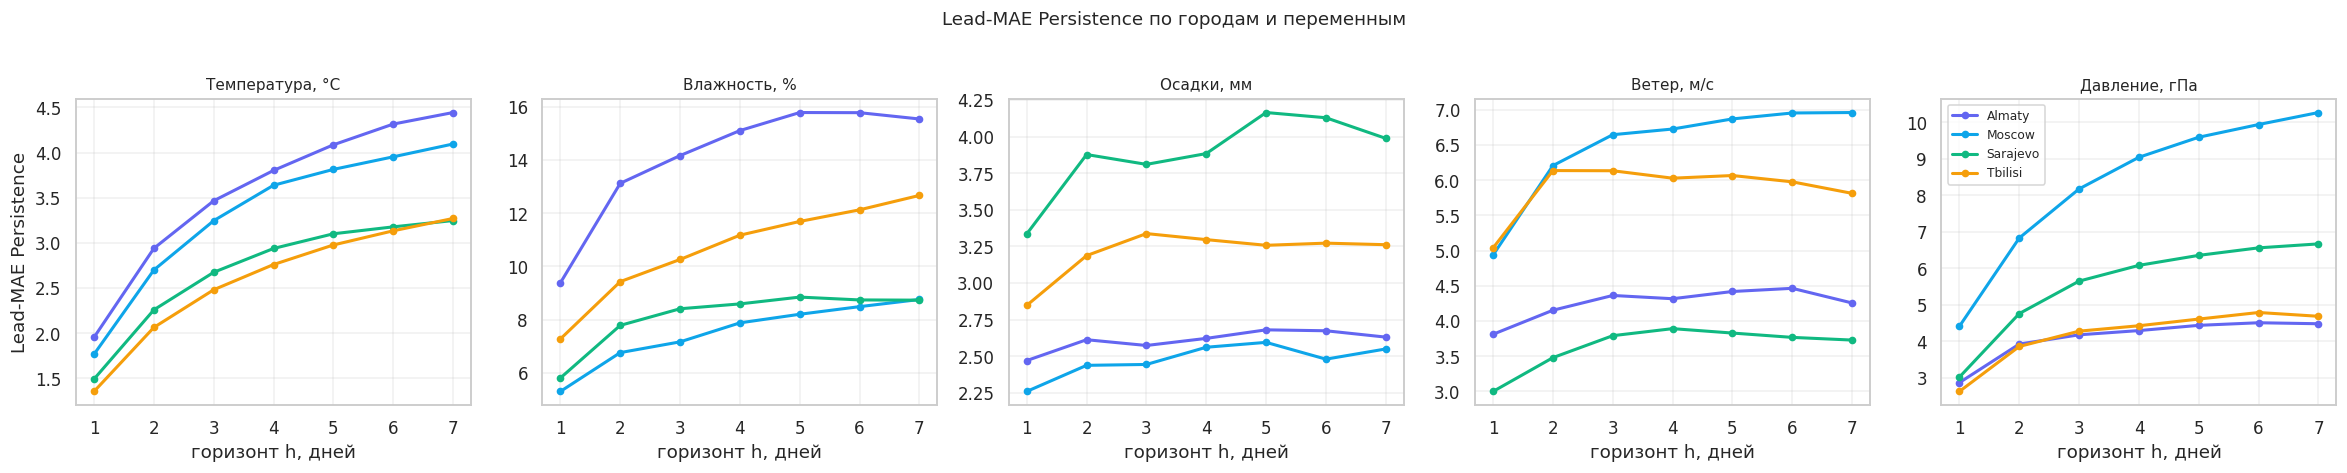

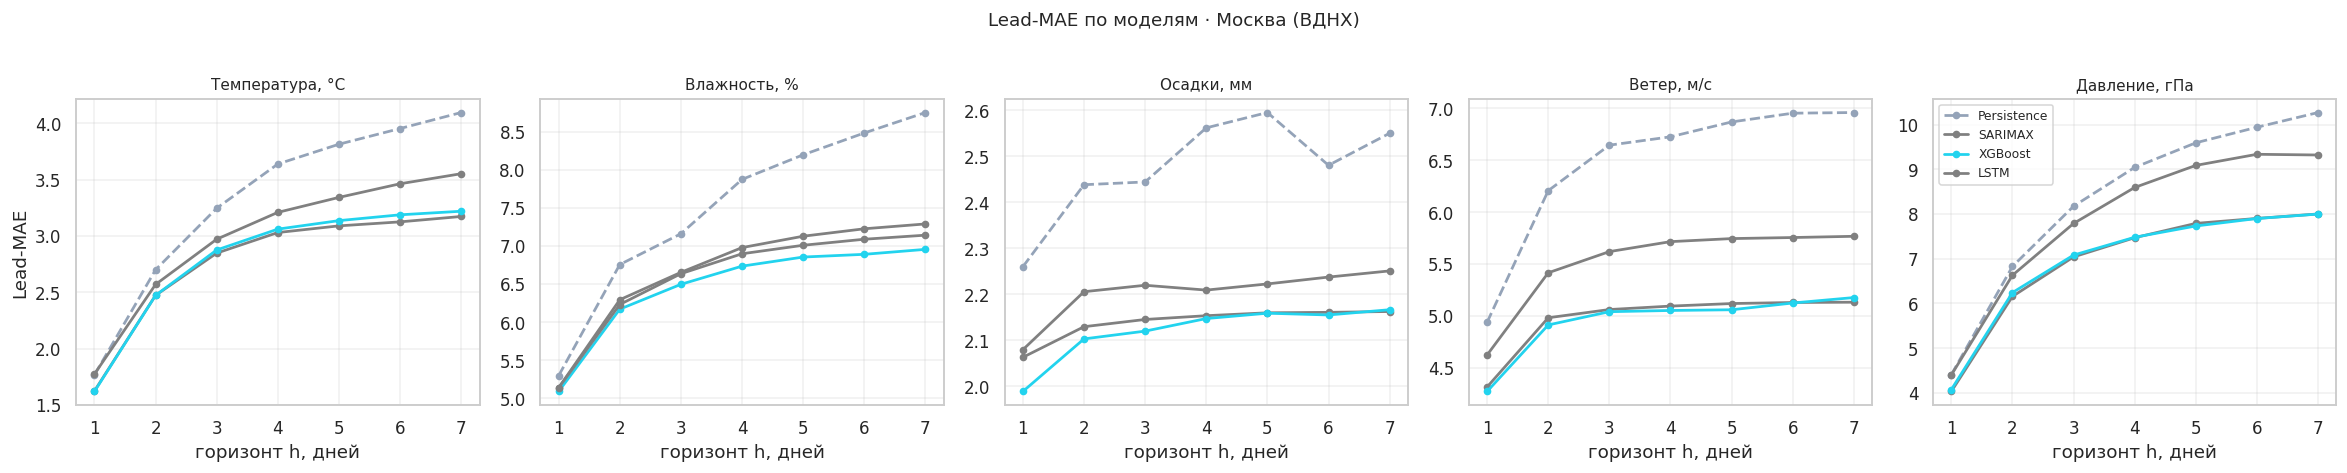

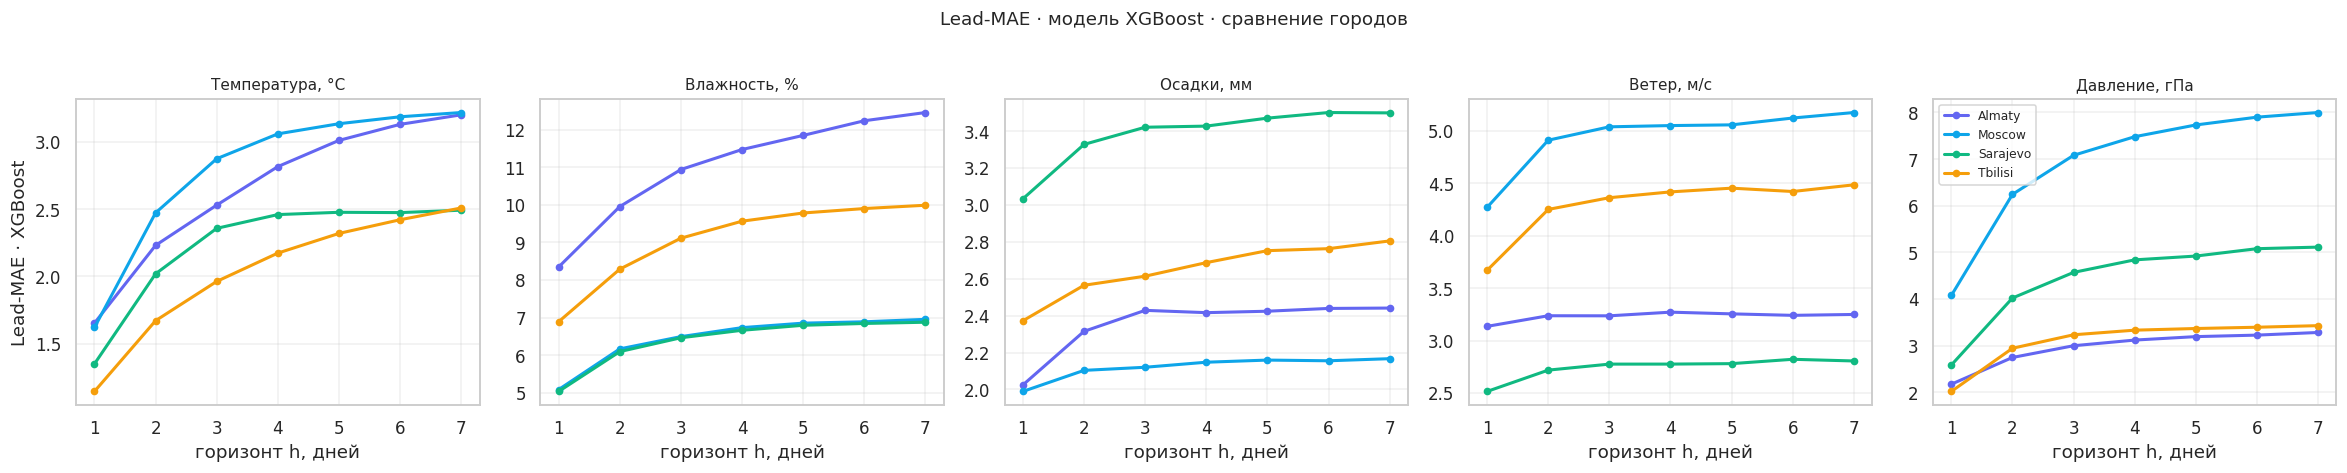

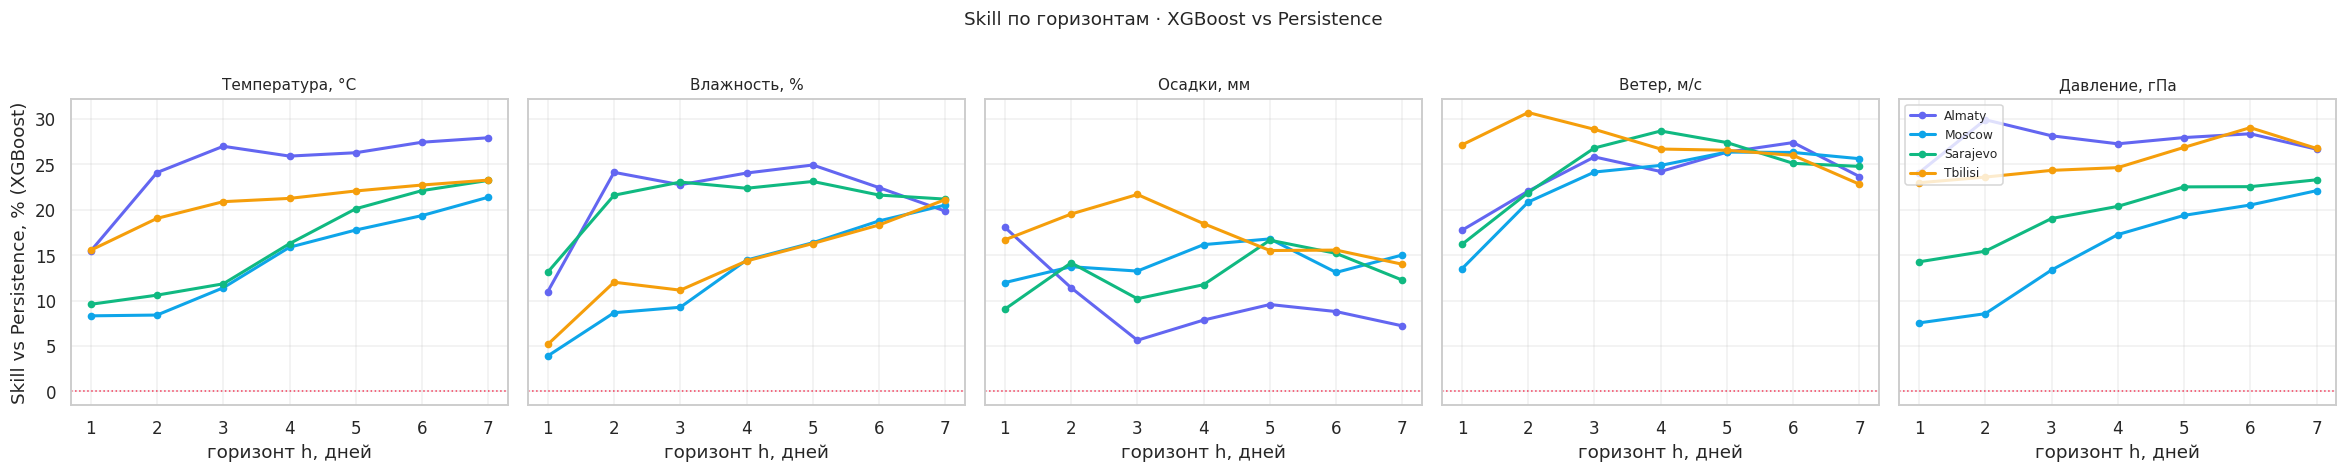

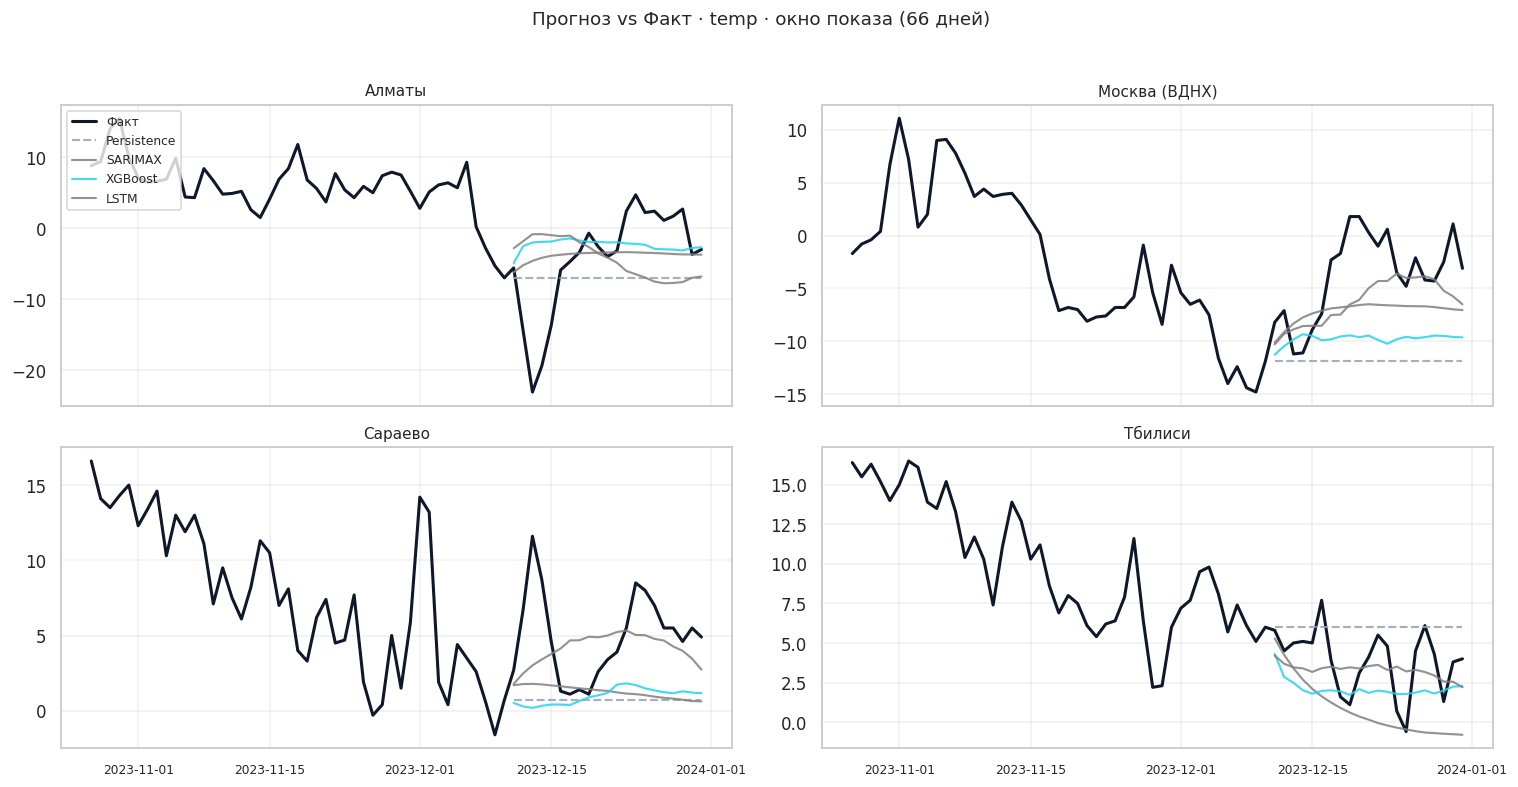


Фигуры сохранены в /app/artifacts/weather/cities/figures


In [10]:
# ============================================================
#  Визуализации city benchmark
#  → artifacts/weather/cities/figures/city_*.png
#
#  Стиль: одна панель = одна переменная, 4 линии = 4 города.
# ============================================================
FIG_DIR = ARTIFACTS_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

VAR_LABELS = {"temp": "Температура, °C", "hum": "Влажность, %",
              "rain": "Осадки, мм", "wind": "Ветер, м/с",
              "pres": "Давление, гПа"}

CITY_COLORS = {
    "Almaty":   "#6366f1",
    "Moscow":   "#0ea5e9",
    "Sarajevo": "#10b981",
    "Tbilisi":  "#f59e0b",
}

# Общий PALETTE для моделей оставим на случай, если он ещё не определён
if "PALETTE" not in dir():
    PALETTE = {
        "Persistence":      "#94a3b8",
        "Seasonal Naive":   "#64748b",
        "Ridge":            "#818cf8",
        "RandomForest":     "#34d399",
        "GradientBoosting": "#fbbf24",
        "XGBoost":          "#22d3ee",
        "SARIMAX":          "#a78bfa",
        "LSTM":             "#f472b6",
    }


# ---------- 6. Lead-MAE по горизонтам: 5 панелей, 4 линии = 4 города ----------
# Для каждой переменной — своя панель. На панели 4 линии (города).
# Используется Persistence-lead, потому что он единственный, кто у всех
# переменных посчитан честно.
fig, axes = plt.subplots(1, len(CITY_VAR_MAP),
                         figsize=(4.3 * len(CITY_VAR_MAP), 4.2),
                         sharey=False)
if len(CITY_VAR_MAP) == 1:
    axes = [axes]

for ax, city_key in zip(axes, CITY_VAR_MAP):
    for city_name in CITY_NAMES:
        vb = city_models_data[city_name]["vars"][city_key]
        lead = vb["leadMae"].get("Persistence", [])[:len(CITY_HORIZONS)]
        if not lead:
            continue
        ax.plot(CITY_HORIZONS, lead,
                marker="o", ms=4, lw=2,
                color=CITY_COLORS.get(city_name, "gray"),
                label=city_name)
    ax.set_title(VAR_LABELS[city_key], fontsize=10)
    ax.set_xlabel("горизонт h, дней")
    ax.set_xticks(CITY_HORIZONS)
    ax.grid(alpha=0.3)

axes[0].set_ylabel("Lead-MAE Persistence")
axes[-1].legend(fontsize=8, loc="upper left")
fig.suptitle("Lead-MAE Persistence по городам и переменным", fontsize=12, y=1.02)
plt.tight_layout()
plt.savefig(FIG_DIR / "city_lead_mae_by_city.png", dpi=110, bbox_inches="tight")
plt.show()


# ---------- 7. Lead-MAE по горизонтам: 5 панелей, N линий = N моделей ----------
# Для одного города (Москва) — вид «кто кого обыгрывает по горизонту».
focus_city = "Moscow" if "Moscow" in CITY_NAMES else CITY_NAMES[0]

fig, axes = plt.subplots(1, len(CITY_VAR_MAP),
                         figsize=(4.3 * len(CITY_VAR_MAP), 4.2),
                         sharey=False)
if len(CITY_VAR_MAP) == 1:
    axes = [axes]

for ax, city_key in zip(axes, CITY_VAR_MAP):
    vb = city_models_data[focus_city]["vars"][city_key]
    for m in CITY_MODELS:
        lead = vb["leadMae"].get(m, [])[:len(CITY_HORIZONS)]
        if not lead:
            continue
        ax.plot(CITY_HORIZONS, lead,
                marker="o", ms=4, lw=1.8,
                color=PALETTE.get(m, "gray"),
                linestyle="--" if m == "Persistence" else "-",
                label=m)
    ax.set_title(VAR_LABELS[city_key], fontsize=10)
    ax.set_xlabel("горизонт h, дней")
    ax.set_xticks(CITY_HORIZONS)
    ax.grid(alpha=0.3)

axes[0].set_ylabel("Lead-MAE")
axes[-1].legend(fontsize=8, loc="upper left")
fig.suptitle(f"Lead-MAE по моделям · {CITY_INFO[focus_city]['city_ru']}",
             fontsize=12, y=1.02)
plt.tight_layout()
plt.savefig(FIG_DIR / f"city_lead_mae_by_model_{focus_city}.png",
            dpi=110, bbox_inches="tight")
plt.show()


# ---------- 8. MAE по горизонтам: 5 панелей × 4 линии (по городам), лучшая модель ----------
# «Лучшая модель» — по лидерборду, если он уже посчитан, иначе XGBoost.
# Лучшая НЕ-baseline модель по лидерборду (если он уже посчитан), иначе XGBoost.
_lb_city = globals().get("leaderboards", {}).get("city", [])
_lb_city = [r["name"] for r in _lb_city if r["name"] != "Persistence"]
best_city_model = (_lb_city[0] if _lb_city and _lb_city[0] in CITY_MODELS
                   else ("XGBoost" if "XGBoost" in CITY_MODELS else CITY_MODELS[-1]))

fig, axes = plt.subplots(1, len(CITY_VAR_MAP),
                         figsize=(4.3 * len(CITY_VAR_MAP), 4.2),
                         sharey=False)
if len(CITY_VAR_MAP) == 1:
    axes = [axes]

for ax, city_key in zip(axes, CITY_VAR_MAP):
    for city_name in CITY_NAMES:
        vb = city_models_data[city_name]["vars"][city_key]
        lead = vb["leadMae"].get(best_city_model, [])[:len(CITY_HORIZONS)]
        if not lead:
            lead = vb["leadMae"].get("Persistence", [])[:len(CITY_HORIZONS)]
        ax.plot(CITY_HORIZONS, lead,
                marker="o", ms=4, lw=2,
                color=CITY_COLORS.get(city_name, "gray"),
                label=city_name)
    ax.set_title(VAR_LABELS[city_key], fontsize=10)
    ax.set_xlabel("горизонт h, дней")
    ax.set_xticks(CITY_HORIZONS)
    ax.grid(alpha=0.3)

axes[0].set_ylabel(f"Lead-MAE · {best_city_model}")
axes[-1].legend(fontsize=8, loc="upper left")
fig.suptitle(f"Lead-MAE · модель {best_city_model} · сравнение городов",
             fontsize=12, y=1.02)
plt.tight_layout()
plt.savefig(FIG_DIR / "city_lead_mae_cities_best_model.png",
            dpi=110, bbox_inches="tight")
plt.show()


# ---------- 9. Skill по горизонтам: 5 панелей, 4 линии = 4 города ----------
# Skill здесь — относительный выигрыш лучшей модели над Persistence
# на конкретном горизонте, для каждой переменной и города.
fig, axes = plt.subplots(1, len(CITY_VAR_MAP),
                         figsize=(4.3 * len(CITY_VAR_MAP), 4.2),
                         sharey=True)
if len(CITY_VAR_MAP) == 1:
    axes = [axes]

for ax, city_key in zip(axes, CITY_VAR_MAP):
    for city_name in CITY_NAMES:
        vb = city_models_data[city_name]["vars"][city_key]
        base_lead = np.array(vb["leadMae"].get("Persistence", [])[:len(CITY_HORIZONS)])
        mod_lead  = np.array(vb["leadMae"].get(best_city_model, [])[:len(CITY_HORIZONS)])
        if base_lead.size == 0 or mod_lead.size == 0:
            continue
        skill = 1 - mod_lead / np.where(base_lead > 0, base_lead, 1)
        ax.plot(CITY_HORIZONS, skill * 100,
                marker="o", ms=4, lw=2,
                color=CITY_COLORS.get(city_name, "gray"),
                label=city_name)
    ax.axhline(0, color="#f43f5e", lw=1, linestyle=":")
    ax.set_title(VAR_LABELS[city_key], fontsize=10)
    ax.set_xlabel("горизонт h, дней")
    ax.set_xticks(CITY_HORIZONS)
    ax.grid(alpha=0.3)

axes[0].set_ylabel(f"Skill vs Persistence, % ({best_city_model})")
axes[-1].legend(fontsize=8, loc="upper left")
fig.suptitle(f"Skill по горизонтам · {best_city_model} vs Persistence",
             fontsize=12, y=1.02)
plt.tight_layout()
plt.savefig(FIG_DIR / "city_skill_by_horizon.png",
            dpi=110, bbox_inches="tight")
plt.show()


# ---------- 10. Forecast vs Actual: temp, все модели, все города ----------
fig, axes = plt.subplots(2, 2, figsize=(14, 7), sharex=True)
for ax, city_name in zip(axes.flat, CITY_NAMES):
    var = city_models_data[city_name]["vars"]["temp"]
    dates = city_models_data[city_name]["dates"]
    x_axis = pd.to_datetime(dates)
    actual = np.array(var["actual"])
    ax.plot(x_axis, actual, color="#0f172a", lw=2, label="Факт")
    for m_idx, m in enumerate(CITY_MODELS):
        fc = var["models"][m_idx]["forecast"]
        fc_arr = np.array([v if v is not None else np.nan for v in fc])
        ax.plot(x_axis[CITY_BACK_START:], fc_arr[CITY_BACK_START:],
                lw=1.4, alpha=0.85,
                color=PALETTE.get(m, "gray"),
                linestyle="--" if m == "Persistence" else "-",
                label=m)
    ax.set_title(CITY_INFO[city_name]["city_ru"], fontsize=10)
    ax.grid(alpha=0.3)
    ax.tick_params(axis="x", labelsize=8)
axes[0, 0].legend(fontsize=8, loc="upper left")
fig.suptitle("Прогноз vs Факт · temp · окно показа (66 дней)",
             fontsize=12, y=1.02)
plt.tight_layout()
plt.savefig(FIG_DIR / "city_temp_forecast_vs_actual.png",
            dpi=110, bbox_inches="tight")
plt.show()


print(f"\nФигуры сохранены в {FIG_DIR}")

In [11]:
# ============================================================
#  Верификация cities.json (файл пишет ячейка 9)
#  НИЧЕГО НЕ ПЕРЕЗАПИСЫВАЕМ.
# ============================================================
import json
from pathlib import Path

CITIES_JSON = ARTIFACTS_DIR / "cities.json"

print("=" * 64)
print("CITIES.JSON — ВЕРИФИКАЦИЯ")
print("=" * 64)

if not CITIES_JSON.exists():
    raise FileNotFoundError(
        f"{CITIES_JSON} не найден. Сначала выполни ячейку 9 (City benchmark)."
    )

data = json.loads(CITIES_JSON.read_text())
size_kb = CITIES_JSON.stat().st_size / 1024
print(f"file: {CITIES_JSON}  ({size_kb:.1f} KB)")

# ---------- 1. Обязательные top-level поля ----------
required_top = [
    "source", "generatedAt", "dates",
    "nPast", "backStart", "origin", "forecastDays",
    "horizons", "variables", "modelNames",
    "cities", "featureImportance",
]
missing = [k for k in required_top if k not in data]
if missing:
    print(f"  ✗ отсутствуют top-level поля: {missing}")
else:
    print(f"  ✓ все top-level поля на месте ({len(required_top)} шт.)")

# ---------- 2. Сводка ----------
print(f"\n  городов         : {len(data['cities'])}")
print(f"  моделей         : {data['modelNames']}")
print(f"  горизонтов      : {data.get('horizons')}")
print(f"  окно показа     : {data['dates'][0]} → {data['dates'][-1]}  "
      f"({len(data['dates'])} дней)")
print(f"  nPast/backStart/origin/forecastDays: "
      f"{data['nPast']}/{data['backStart']}/{data['origin']}/{data['forecastDays']}")

# ---------- 3. Проверка структуры городов ----------
print("\n  По городам:")
ok_all = True
for c in data["cities"]:
    name_ru = c.get("name")
    name_en = c.get("nameEn")
    if not name_en:
        # fallback, если nameEn ещё не сохранён
        name_en = name_ru
    n_dates = len(c.get("dates", []))
    n_vars = len(c.get("vars", {}))
    vars_ok = all(
        isinstance(v, dict) and
        "actual" in v and "models" in v and
        "leadMae" in v and "metricsByHorizon" in v
        for v in c.get("vars", {}).values()
    )
    status = "✓" if (n_dates == len(data["dates"]) and vars_ok) else "✗"
    if status == "✗":
        ok_all = False
    print(f"    {status} {name_ru:<15} ({name_en:<10})  "
          f"dates={n_dates}  vars={n_vars}  struct_ok={vars_ok}")

# ---------- 4. Sanity по Almaty / temp ----------
print("\n  Sanity · Almaty / temp (1-step metrics, полный тест):")
c0 = next((c for c in data["cities"]
           if c.get("nameEn") == "Almaty" or c.get("name") == "Almaty"), None)
if c0 is None:
    c0 = data["cities"][0]

var = c0["vars"]["temp"]
print(f"    leadMae:")
for mname, arr in var["leadMae"].items():
    s = "  ".join(f"h{i+1}={v:.2f}" for i, v in enumerate(arr))
    print(f"      {mname:<12} {s}")

print(f"\n    metrics (1-step, полный тест):")
for m in var["models"]:
    mm = m["metrics"]
    win = m.get("metricsWindow", {})
    print(f"      {m['name']:<12} MAE={mm['mae']:.3f}  "
          f"RMSE={mm['rmse']:.3f}  R²={mm['r2']:.3f}  "
          f"skill={mm['skill']:+.3f}  (n={win.get('n', '?')})")

print(f"\n    metricsByHorizon · skill по h:")
for mname, by_h in var["metricsByHorizon"].items():
    cells = []
    for h in sorted(by_h.keys(), key=int):
        s = by_h[h].get("skill", 0.0)
        cells.append(f"h{h}={s:+.3f}")
    print(f"      {mname:<12} {'  '.join(cells)}")

# ---------- 5. Проверка sd(h) ----------
print(f"\n  Sanity · sd(h) для Almaty/temp (первые 3 дня после backStart):")
for m in var["models"]:
    sd = m.get("sd") or []
    if len(sd) > data["backStart"]:
        head = sd[data["backStart"]:data["backStart"] + 3]
        print(f"    {m['name']:<12} sd[{data['backStart']}..] = {head}")

# ---------- 6. Feature importance ----------
fi = data.get("featureImportance") or {}
if fi:
    top_city = next(iter(fi))
    print(f"\n  featureImportance: {len(fi)} городов × "
          f"{len(fi[top_city])} переменных (e.g. {top_city}/temp top-3):")
    for item in fi[top_city].get("temp", [])[:3]:
        print(f"    {item['name']:<15} {item['value']:.4f}")
else:
    print("\n  ✗ featureImportance пуст или отсутствует")

# ---------- 7. Итог ----------
print("\n" + "=" * 64)
if missing:
    print("СТАТУС: ✗ cities.json неполный — сначала выполни ячейку 9")
else:
    print("СТАТУС: ✓ cities.json валиден, фронт может читать")
print("=" * 64)

CITIES.JSON — ВЕРИФИКАЦИЯ
file: /app/artifacts/weather/cities/cities.json  (585.3 KB)
  ✓ все top-level поля на месте (12 шт.)

  городов         : 4
  моделей         : ['Persistence', 'SARIMAX', 'XGBoost', 'LSTM']
  горизонтов      : [1, 2, 3, 4, 5, 6, 7]
  окно показа     : 2023-10-27 → 2023-12-31  (66 дней)
  nPast/backStart/origin/forecastDays: 59/45/44/7

  По городам:
    ✓ Алматы          (Almaty    )  dates=66  vars=5  struct_ok=True
    ✓ Москва (ВДНХ)   (Moscow    )  dates=66  vars=5  struct_ok=True
    ✓ Сараево         (Sarajevo  )  dates=66  vars=5  struct_ok=True
    ✓ Тбилиси         (Tbilisi   )  dates=66  vars=5  struct_ok=True

  Sanity · Almaty / temp (1-step metrics, полный тест):
    leadMae:
      Persistence  h1=1.95  h2=2.94  h3=3.47  h4=3.80  h5=4.09  h6=4.32  h7=4.44
      SARIMAX      h1=1.95  h2=2.89  h3=3.31  h4=3.57  h5=3.76  h6=3.86  h7=3.92
      XGBoost      h1=1.65  h2=2.23  h3=2.53  h4=2.82  h5=3.01  h6=3.13  h7=3.20
      LSTM         h1=2.18  h2=3.

In [12]:
# ============================================================
#  Leaderboard: ожидается компонентом ModelsPage
#  Формат: { station: [...], city: [...] } — отсортировано по skill ↓
#
#  Исправления:
#   * station: mae/rmse/r2/skill усредняются по ОДНОМУ набору горизонтов
#     (h=1..10); значения по всем 14 — в *AllHorizons.
#   * city: переменные имеют разные единицы (°C, %, мм, м/с, гПа), поэтому
#     mae/rmse усредняются в σ-единицах (ошибка / σ факта на тесте).
#     Всё усредняется по h=1..7 из metricsByHorizon (раньше — только h=1).
#     Сырые MAE — в byVariable (среднее по ВСЕМ городам, а не по первому).
# ============================================================
AGG_HORIZONS = [h for h in STATION_HORIZONS if h <= 10]


def _mean(xs):
    xs = [float(x) for x in xs]
    return float(np.mean(xs)) if xs else 0.0


# --- Station ranking --------------------------------------------------
station_ranking = []
for m in STATION_MODELS:
    cells_all, cells_agg = [], []
    skill_by_horizon = {h: [] for h in STATION_HORIZONS}
    for city_name in CITY_NAMES:
        evals = station_results[city_name].get(m)
        if not evals:
            continue
        for h in STATION_HORIZONS:
            cell = evals.get(h) or evals.get(str(h))
            if cell and cell.get("points") and cell.get("metrics"):
                mtr = cell["metrics"]
                cells_all.append(mtr)
                if h in AGG_HORIZONS:
                    cells_agg.append(mtr)
                skill_by_horizon[h].append(mtr["skill"])
    if not cells_all:
        continue
    station_ranking.append({
        "name": m,
        "mae":   _mean(c["mae"]  for c in cells_agg),
        "rmse":  _mean(c["rmse"] for c in cells_agg),
        "r2":    _mean(c["r2"]   for c in cells_agg),
        "skill": _mean(c["skill"] for c in cells_agg),
        "maeAllHorizons":   _mean(c["mae"]   for c in cells_all),
        "skillAllHorizons": _mean(c["skill"] for c in cells_all),
        "skillByHorizon": {
            str(h): (_mean(v) if v else 0.0) for h, v in skill_by_horizon.items()
        },
        "baseline": m in STATION_BASELINES,
    })


# --- City ranking -----------------------------------------------------
city_ranking = []
for m in CITY_MODELS:
    per_cv = []                                  # по (город, переменная)
    by_var_raw = {k: [] for k in CITY_VAR_MAP}
    by_var_skill = {k: [] for k in CITY_VAR_MAP}
    for city_name in CITY_NAMES:
        for key in CITY_VAR_MAP:
            vb = city_models_data[city_name]["vars"][key]
            by_h = vb["metricsByHorizon"].get(m)
            if not by_h:
                continue
            cells = [by_h[str(h)] for h in CITY_HORIZONS if str(h) in by_h]
            sigma = city_var_sigma.get((city_name, key), 1.0)
            per_cv.append({
                "mae":   _mean(c["mae"]  for c in cells) / sigma,
                "rmse":  _mean(c["rmse"] for c in cells) / sigma,
                "r2":    _mean(c["r2"]   for c in cells),
                "skill": _mean(c["skill"] for c in cells),
                "skill1": float(by_h["1"]["skill"]) if "1" in by_h else 0.0,
            })
            by_var_raw[key].append(_mean(c["mae"] for c in cells))
            by_var_skill[key].append(_mean(c["skill"] for c in cells))
    if not per_cv:
        continue
    city_ranking.append({
        "name":  m,
        "mae":   _mean(x["mae"]  for x in per_cv),     # в σ-единицах (безразмерная)
        "rmse":  _mean(x["rmse"] for x in per_cv),     # в σ-единицах
        "r2":    _mean(x["r2"]   for x in per_cv),
        "skill": _mean(x["skill"] for x in per_cv),    # среднее по h=1..7
        "skill1": _mean(x["skill1"] for x in per_cv),  # только h=1
        "byVariable": {
            k: {"mae": _mean(by_var_raw[k]), "skill": _mean(by_var_skill[k]),
                "unit": CITY_VAR_UNITS[k]}
            for k in CITY_VAR_MAP if by_var_raw[k]
        },
        "baseline": m == "Persistence",
    })

leaderboards = {
    "generatedAt": datetime.now().isoformat(),
    "aggregationHorizons": AGG_HORIZONS,
    "cityAggregationHorizons": CITY_HORIZONS,
    "note": (
        "station: mae/rmse/r2/skill усреднены по h=1..10 (на h=11..14 метрика шумная); "
        "*AllHorizons — по всем 14. "
        "city: mae/rmse — в σ-единицах (ошибка / σ факта), т.к. переменные в разных "
        "единицах; mae/rmse/r2/skill усреднены по h=1..7; byVariable.mae — сырой MAE "
        "в единицах переменной, среднее по всем городам."
    ),
    "station": sorted(station_ranking, key=lambda r: -r["skill"]),
    "city":    sorted(city_ranking,    key=lambda r: -r["skill"]),
}

out_path = ARTIFACTS_DIR / "leaderboards.json"
out_path.write_text(json.dumps(leaderboards, indent=2, ensure_ascii=False))
print(f"saved → {out_path}  ({out_path.stat().st_size/1024:.1f} KB)\n")

print(f"Station ranking (skill по h∈{AGG_HORIZONS} ↓):")
for r in leaderboards["station"]:
    tag = "baseline" if r["baseline"] else "        "
    print(f"  {r['name']:18s} {tag}  MAE={r['mae']:.3f}  "
          f"skill={r['skill']:+.3f}  (all-h: {r['skillAllHorizons']:+.3f})")

print(f"\nCity ranking (skill по h∈{CITY_HORIZONS} ↓; MAE в σ-единицах):")
for r in leaderboards["city"]:
    tag = "baseline" if r["baseline"] else "        "
    print(f"  {r['name']:18s} {tag}  nMAE={r['mae']:.3f}  "
          f"skill={r['skill']:+.3f}  (h=1: {r['skill1']:+.3f})")


saved → /app/artifacts/weather/cities/leaderboards.json  (8.5 KB)

Station ranking (skill по h∈[1, 2, 3, 4, 5, 6, 7, 8, 9, 10] ↓):
  XGBoost                      MAE=2.565  skill=+0.218  (all-h: +0.239)
  Ridge                        MAE=2.563  skill=+0.217  (all-h: +0.240)
  GradientBoosting             MAE=2.581  skill=+0.212  (all-h: +0.234)
  RandomForest                 MAE=2.587  skill=+0.209  (all-h: +0.231)
  Persistence        baseline  MAE=3.313  skill=+0.000  (all-h: +0.000)
  Seasonal Naive     baseline  MAE=4.221  skill=-0.368  (all-h: -0.262)

City ranking (skill по h∈[1, 2, 3, 4, 5, 6, 7] ↓; MAE в σ-единицах):
  XGBoost                      nMAE=0.566  skill=+0.193  (h=1: +0.141)
  SARIMAX                      nMAE=0.599  skill=+0.141  (h=1: +0.075)
  LSTM                         nMAE=0.618  skill=+0.117  (h=1: +0.056)
  Persistence        baseline  nMAE=0.710  skill=+0.000  (h=1: +0.000)


In [13]:
# ============================================================
#  Верификация артефактов (stations + cities + leaderboards)
#  Ничего не пишет — только читает и проверяет.
# ============================================================
import json
import math

print("=" * 64)
print("ВЕРИФИКАЦИЯ АРТЕФАКТОВ")
print("=" * 64)

ok = True


def _check(cond: bool, msg_ok: str, msg_fail: str) -> None:
    global ok
    if cond:
        print(f"      ✓ {msg_ok}")
    else:
        print(f"      ✗ {msg_fail}")
        ok = False


def _fmt_size(p) -> str:
    size = p.stat().st_size / 1024
    return f"{size:.1f} KB" if size < 1024 else f"{size/1024:.1f} MB"


for fname in ["stations.json", "cities.json", "leaderboards.json"]:
    p = ARTIFACTS_DIR / fname
    if not p.exists():
        print(f"\n  ✗ {fname} — отсутствует")
        ok = False
        continue
    try:
        data = json.loads(p.read_text())
    except Exception as e:
        print(f"\n  ✗ {fname} — не парсится: {e}")
        ok = False
        continue

    print(f"\n  ✓ {fname}  ({_fmt_size(p)})")

    # ==========================================================
    #  stations.json
    # ==========================================================
    if fname == "stations.json":
        sd       = data["stationData"]
        models   = [m["name"] for m in data["models"]]
        horizons = data["horizons"]
        print(f"      станций    : {len(sd)}")
        print(f"      моделей    : {models}")
        print(f"      горизонтов : {len(horizons)}")

        for st in sd:
            st_label = st["station"]["label"]
            evals    = st["evaluations"]
            n_full   = 0
            for m in models:
                if m not in evals:
                    continue
                has_all = all(
                    (evals[m].get(str(h)) or evals[m].get(h))
                    and (evals[m].get(str(h)) or evals[m].get(h)).get("points")
                    for h in horizons
                )
                if has_all:
                    n_full += 1
            print(f"      · {st_label:15s} моделей с полным бэктестом: "
                  f"{n_full}/{len(models)}")
            if n_full == 0:
                ok = False

        first_st  = sd[0]["evaluations"]
        first_m   = next(iter(first_st))
        sample_h1 = first_st[first_m]["1"]
        missing = []
        if "deltaVsPersistence" not in sample_h1:
            missing.append("deltaVsPersistence")
        if "metrics" not in sample_h1 or not sample_h1["metrics"]:
            missing.append("metrics")
        if "points" not in sample_h1 or not sample_h1["points"]:
            missing.append("points")
        _check(
            not missing,
            "обязательные поля на месте (deltaVsPersistence, metrics, points)",
            f"отсутствуют поля: {missing}",
        )

        if "pointsPerHorizon" in data:
            print(f"      ✓ pointsPerHorizon: {data['pointsPerHorizon']}")

    # ==========================================================
    #  cities.json  (расширенная проверка)
    # ==========================================================
    if fname == "cities.json":
        # --- top-level ---
        print(f"      городов    : {len(data['cities'])}")
        print(f"      окно показа: {data['dates'][0]} → {data['dates'][-1]}  "
              f"({len(data['dates'])} дней)")
        print(f"      моделей    : {data['modelNames']}")
        ms = data.get("metricsSource", {})
        if ms:
            print(f"      окно метрик: {ms.get('period')}  "
                  f"({ms.get('n_days')} дней)")

        # --- новые top-level поля ---
        for k in ("horizons", "featureImportance", "dates"):
            _check(k in data, f"top-level '{k}' присутствует",
                   f"top-level '{k}' ОТСУТСТВУЕТ — cities.json устарел")

        if "horizons" in data:
            print(f"      горизонты  : {data['horizons']}")

        fi = data.get("featureImportance") or {}
        if fi:
            c_first = next(iter(fi))
            print(f"      featureImportance: {len(fi)} городов × "
                  f"{len(fi[c_first])} переменных")

        # --- по городам / переменным ---
        required_var_fields = ("actual", "models", "leadMae", "metricsByHorizon")
        for c in data["cities"]:
            name_ru = c.get("name")
            name_en = c.get("nameEn")
            _check(
                name_en is not None,
                f"nameEn '{name_en}' у {name_ru}",
                f"nameEn отсутствует у '{name_ru}'",
            )
            # русское имя (не должно совпадать с nameEn латиницей)
            if name_en and name_ru and name_ru == name_en:
                print(f"      ⚠ name == nameEn = '{name_ru}' — "
                      f"русское имя не подставлено")

            for var in c["vars"]:
                vb = c["vars"][var]
                miss_var = [k for k in required_var_fields if k not in vb]
                if miss_var:
                    print(f"      ✗ {name_ru} / {var}: нет полей {miss_var}")
                    ok = False
                    continue

                n_models = len(vb["models"])
                # forecast_points — сколько не-None в первом блоке
                fc0   = vb["models"][0]["forecast"]
                n_pts = sum(1 for v in fc0 if v is not None)

                # leadMae по всем моделям
                has_lead = all(
                    isinstance(vb["leadMae"].get(m["name"]), list)
                    and len(vb["leadMae"][m["name"]]) == len(data.get("horizons", [1,2,3,4,5,6,7]))
                    for m in vb["models"]
                )
                # metricsByHorizon по всем моделям
                has_mbh = all(
                    isinstance(vb["metricsByHorizon"].get(m["name"]), dict)
                    and len(vb["metricsByHorizon"][m["name"]]) > 0
                    for m in vb["models"]
                )
                has_metrics = all("metrics" in m and m["metrics"]
                                  for m in vb["models"])

                mark = "✓" if (has_metrics and has_lead and has_mbh) else "✗"
                if mark == "✗":
                    ok = False
                print(f"      {mark} {name_ru:12s} {var:5s} "
                      f"models={n_models}  fc_pts={n_pts}  "
                      f"leadMae={has_lead}  metricsByHorizon={has_mbh}")

                # sanity: MAE temp не 13+
                for m in vb["models"]:
                    mae = m["metrics"].get("mae", 0.0)
                    if var == "temp" and mae > 10:
                        print(f"        ⚠ {m['name']} MAE={mae:.2f} — "
                              f"подозрительно много")

                # sanity: skill в metricsByHorizon не 0.0 для ML (кроме Persistence)
                if var == "temp":
                    for mname, by_h in vb["metricsByHorizon"].items():
                        if mname == "Persistence":
                            continue
                        skills = [v.get("skill", 0.0) for v in by_h.values()]
                        if skills and all(abs(s) < 1e-9 for s in skills):
                            print(f"        ⚠ {mname}: skill=0.0 по всем h — "
                                  f"baseline не прокинут в compute_metrics")

                # sanity: sd(h) — не все None
                if var == "temp":
                    sd_arr = vb["models"][-1].get("sd") or []
                    n_sd = sum(1 for v in sd_arr if v is not None)
                    if n_sd == 0:
                        print(f"        ⚠ sd(h) пуст — resid_std не пробрасывается")

    # ==========================================================
    #  leaderboards.json
    # ==========================================================
    if fname == "leaderboards.json":
        agg = data.get("aggregationHorizons", "—")
        print(f"      агрегация по h∈{agg}")
        for section in ("station", "city"):
            rows = data.get(section, [])
            print(f"      · {section}: {len(rows)} моделей")
            if not rows:
                ok = False
            else:
                top = rows[0]
                print(f"        лидер: {top['name']}  "
                      f"skill={top['skill']:+.3f}  MAE={top['mae']:.3f}")

# ----------------------------------------------------------
print("\n" + "=" * 64)
if ok:
    print("ВСЁ ОК — фронт может читать:")
else:
    print("⚠ ЕСТЬ ЗАМЕЧАНИЯ — см. выше:")
print("  /artifacts/weather/cities/stations.json")
print("  /artifacts/weather/cities/cities.json")
print("  /artifacts/weather/cities/leaderboards.json")
print("=" * 64)

ВЕРИФИКАЦИЯ АРТЕФАКТОВ

  ✓ stations.json  (4.8 MB)
      станций    : 4
      моделей    : ['Persistence', 'Seasonal Naive', 'Ridge', 'RandomForest', 'GradientBoosting', 'XGBoost']
      горизонтов : 14
      · Алматы          моделей с полным бэктестом: 6/6
      · Москва (ВДНХ)   моделей с полным бэктестом: 6/6
      · Сараево         моделей с полным бэктестом: 6/6
      · Тбилиси         моделей с полным бэктестом: 6/6
      ✓ обязательные поля на месте (deltaVsPersistence, metrics, points)
      ✓ pointsPerHorizon: 100

  ✓ cities.json  (585.3 KB)
      городов    : 4
      окно показа: 2023-10-27 → 2023-12-31  (66 дней)
      моделей    : ['Persistence', 'SARIMAX', 'XGBoost', 'LSTM']
      окно метрик: 2022-01-01 → 2023-12-31  (730 дней)
      ✓ top-level 'horizons' присутствует
      ✓ top-level 'featureImportance' присутствует
      ✓ top-level 'dates' присутствует
      горизонты  : [1, 2, 3, 4, 5, 6, 7]
      featureImportance: 4 городов × 5 переменных
      ✓ nameEn 'Almaty